(multisite-transfer)=
# Multisite Model Transfer


### site_transfer_utils.<br>**multisite_transfer**

```python
multisite_transfer(main_model_path, main_traindata, df2, new_sites, selected_sites, sample_sizes, 
                   y_val, x_vals, iterations=100, save_folder=None, file_name=None,
                   affected=None, affected_col_name='affected',
                   sampling_strategy='stratified_age', sampling_params=None, params_to_adjust=None,
                   treat_missing_as_healthy=False, pin_unadjusted_params=False,
                   adjustment_covariates=None, covariate_params=None)
```

&nbsp;&nbsp;&nbsp;&nbsp;Transfers a GAMLSS model trained on one site to multiple new sites with site-specific adjustments. Uses healthy samples from new sites to fit adjustment models that account for site differences. **Supports multiple sampling strategies to ensure representative coverage across age ranges.** Automatically saves adjustment models with descriptive filenames.

&nbsp;&nbsp;&nbsp;&nbsp;<span style="background-color: #f5f5f5; padding: 4px 8px; display: inline-block; width: 90%;">**Parameters:**</span>

&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;**main_model_path** : ***str*** <br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;Path to the main GAMLSS model (.rds file)

&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;**main_traindata** : ***pandas.DataFrame*** <br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;Training dataset for the main model (must include all x_vals and y_val)

&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;**df2** : ***pandas.DataFrame*** <br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;Test dataset (must include 'site' column). If `affected` parameter is not provided, <br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;should include a column for identifying healthy subjects (default: 'affected')

&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;**new_sites** : ***list of str*** <br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;List of new sites to transfer to (sites not in training data)

&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;**selected_sites** : ***str or list of str*** <br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;Single proxy site or list of proxy sites (same length as new_sites). <br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;Proxy sites must exist in training data.

&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;**sample_sizes** : ***float, int, or list*** <br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;Single value or list of values per site (same length as new_sites). <br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;If 0 < value < 1, treated as a fraction of healthy samples (e.g., 0.2 = 20%). <br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;If value >= 1, treated as an absolute number of samples (e.g., 50 = 50 subjects).

&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;**y_val** : ***str*** <br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;Name of the target variable

&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;**x_vals** : ***list of str*** <br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;List of predictor variable names (must include 'site')

&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;**iterations** : ***int***, *default=100* <br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;Number of iterations for the adjustment model fitting

&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;**save_folder** : ***str***, *optional* <br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;Folder path to save results and models. If provided, creates: <br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;- `{save_folder}/adjustment_models/` for .rds model files <br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;- `{save_folder}/{file_name}` for results dictionary

&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;**file_name** : ***str***, *optional* <br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;File name to save results dictionary (e.g., 'results.pkl')

&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;**affected** : ***array-like***, *optional* <br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;Array indicating affected status for all subjects in df2 (same length as df2). <br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;If None, attempts to use column specified by `affected_col_name` from df2. <br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;If neither exists, assumes all subjects are healthy. <br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;**Supported formats:** <br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;- The literal string 'None' → always healthy (this notebook's convention) <br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;- Binary: 0 → healthy, 1 → affected <br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;- String: `'healthy'`, `'healthy control(s)'` or `'control(s)'` as the whole label (any case) → healthy; other labels that mention 'healthy' or 'control' (e.g. 'healthy subject', 'unhealthy') → error asking you to rename them; any other string → affected <br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;- Genuinely missing (NaN) → **raises** by default; see treat_missing_as_healthy below

&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;**affected_col_name** : ***str***, *default='affected'* <br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;Name of the column in df2 to use for identifying healthy subjects. <br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;Only used if `affected` parameter is None.

&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;**sampling_strategy** : ***str***, *default='stratified_age'* <br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;Sampling strategy to use for selecting training samples from new sites. <br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;**Options:** <br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;- `'random'`: Simple random sampling (baseline) <br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;- `'stratified_age'`: **Recommended** - Ensures uniform coverage across age bins <br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;- `'uniform_age'`: Samples uniformly across age range with jitter <br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;- `'stratified_multi'`: Stratifies by multiple features (age, sex, etc.)

&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;**sampling_params** : ***dict***, *optional* <br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;Parameters for the selected sampling strategy. If None, uses defaults. <br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;**For 'random':** <br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;`{'random_state': 42}` <br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;**For 'stratified_age':** (default) <br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;`{'age_col': 'age', 'n_bins': 10, 'random_state': 42}` <br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;**For 'uniform_age':** <br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;`{'age_col': 'age', 'jitter_range': 2, 'random_state': 42}` <br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;**For 'stratified_multi':** <br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;`{'stratify_cols': ['age', 'sex'], 'age_col': 'age', 'n_age_bins': 5, 'random_state': 42}`

&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;**params_to_adjust** : ***list***, *optional* <br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;List of distribution parameters to fit and adjust in the transfer model. <br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;If None (default), fits and adjusts all available parameters. <br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;**Examples:** <br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;- `['mu']` — adjust location only <br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;- `['mu', 'sigma']` — adjust location and scale <br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;- `['mu', 'sigma', 'nu', 'tau']` — adjust all four parameters

&nbsp;&nbsp;&nbsp;&nbsp;**adjustment_covariates** : ***list of str***, *optional* <br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;Column names to include as fixed effects in the GAM refit formula. <br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;If None (default), the refit formula is unchanged (scalar intercept only, `adjust_predictions()` is used). <br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;If set, the listed columns are added as fixed-effect terms in the refit formula and a per-subject adjustment is computed instead (`adjust_predictions_covariate()` is used). <br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;**Examples:** <br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;- `['field_strength']` — adjust for scanner field strength differences across sites

&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;**covariate_params** : ***list of str***, *optional* <br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;Which distribution parameters receive the `adjustment_covariates` terms in the refit. Ignored when `adjustment_covariates` is None. <br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;If None (default), every adjusted parameter does. Pass e.g. `['mu']` to put the covariate on the location only (the other adjusted parameters then get a plain intercept adjustment). <br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;Must be a subset of `params_to_adjust`; a bare string raises an error (use `['mu']`, not `'mu'`).

&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;**treat_missing_as_healthy** : ***bool***, *default=False* <br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;Whether subjects with genuinely missing (NaN) affected status are counted as healthy. <br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;Default raises a ValueError naming how many are missing. Has no effect on the literal <br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;string 'None', which is always healthy regardless of this flag.

&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;**pin_unadjusted_params** : ***bool***, *default=False* <br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;Whether parameters left out of params_to_adjust are held fixed at the main model's <br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;predictions during the refit, instead of being refit as free constants. Default keeps <br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;the free refit (a warning names which parameters this applies to).

&nbsp;&nbsp;&nbsp;&nbsp;<span style="background-color: #f5f5f5; padding: 4px 8px; display: inline-block; width: 90%;">**Returns:**</span>

&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;**results** : ***dict*** <br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;Dictionary with each new site as key containing: <br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;- **'unadjusted_predictions'**: *DataFrame* - Original predictions using main model <br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;- **'adjusted_predictions'**: *DataFrame* - Predictions after site-specific adjustment <br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;- **'z_scores'**: *ndarray* - Z-scores from adjusted predictions <br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;- **'train_set_index'**: *list* - Indices of samples used for training adjustment <br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;- **'selected_site'**: *str* - Proxy site used for transfer <br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;- **'sample_size'**: *float or int* - Sample size used for adjustment <br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;- **'sampling_strategy'**: *str* - Sampling strategy used <br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;- **'sampling_params'**: *dict* - Parameters used for sampling <br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;- **'params_to_adjust'**: *list or None* - Distribution parameters that were adjusted <br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;- **'gam_refit_model_path'**: *str* or *None* - Path to saved adjustment model <br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;Format: `{save_folder}/adjustment_models/gam_refit_{site}_{sample_size_label}.rds` <br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;- **'train_set_positions'**: *ndarray* - Positions of the calibration subjects within <br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;'z_scores' (train_set_index above is a row LABEL; z_scores is POSITIONAL - use this, <br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;not train_set_index, to mask z_scores) <br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;- **'z_scores_heldout'**: *ndarray* - z_scores with calibration subjects already removed <br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;- **'n_requested'** / **'n_realised'**: *int* - Calibration size asked for vs. returned <br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;- **'converged'**: *bool* - Whether the adjustment refit converged <br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;- **'site_index'**: *pandas.Index* - Index of the site's rows in df2, to map between z_scores positions and df2 labels <br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;- **'adjustment_covariates'** / **'covariate_params'**: *list or None* - As passed, so the scoring methods can be called with the same covariates

&nbsp;&nbsp;&nbsp;&nbsp;<span style="background-color: #f5f5f5; padding: 4px 8px; display: inline-block; width: 90%;">**File Structure Created:**</span>

```
save_folder/
├── adjustment_models/                    # Auto-created subfolder
│   ├── gam_refit_OTLIE_20.rds           # Site: OTLIE, sample_size: 0.2 or 20
│   ├── gam_refit_KEMUB_20.rds           # Site: KEMUB, sample_size: 0.2 or 20
│   ├── gam_refit_ZSCPY_20.rds           # Site: ZSCPY, sample_size: 0.2 or 20
│   └── gam_refit_HLMEG_20.rds           # Site: HLMEG, sample_size: 0.2 or 20
└── multi_site_transfer_results.pkl      # Results dictionary
```

&nbsp;&nbsp;&nbsp;&nbsp;<span style="background-color: #f5f5f5; padding: 4px 8px; display: inline-block; width: 90%;">**Important Notes:**</span>

&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;**🎯 Sampling Strategy Recommendations:**
- **Use `'stratified_age'`** (default) for datasets with non-uniform age distributions
- Particularly important when elderly or young subjects are sparse
- Ensures representative coverage across the entire age range
- Critical for robust model transfer in biomedical applications

&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;**⚠️ Why Sampling Strategy Matters:**
- Random sampling can miss sparse age groups (e.g., elderly subjects)
- Non-linear models require samples across the full feature space
- Poor sampling leads to biased transfer adjustments
- See tutorial for detailed comparison of strategies

<br>

**Examples:**

### Toy Data Simulation
Creating data with outliers in the test domain to clearly demonstrate the working of this function

In [92]:
import os

from normgamlss.utils import check_test_sites

# ============================================================================
# MULTISITE MODEL TRANSFER TUTORIAL - NON-LINEAR DATA WITH IMPROVED SAMPLING
# ============================================================================

import numpy as np
import pandas as pd
import string
import random
import matplotlib.pyplot as plt
from normgamlss.gamlss_main import Gamlss
from normgamlss.site_transfer_utils import (
    multisite_transfer, 
    stratified_age_sampling,
    uniform_age_sampling,
    random_sampling,
    plot_sampling_coverage
)

In [93]:
# ============================================================================
# SECTION 1: GENERATE NON-LINEAR TOY DATA WITH NON-UNIFORM DISTRIBUTION
# ============================================================================

print("="*70)
print("SECTION 1: GENERATING REALISTIC NON-LINEAR TOY DATA")
print("="*70)

import numpy as np
import pandas as pd
import string
import random
import matplotlib.pyplot as plt
from scipy import stats as scipy_stats

def generate_random_site_id(length, seed):
    """Generate random site ID with fixed seed."""
    random.seed(seed)
    letters = string.ascii_uppercase
    return ''.join(random.choice(letters) for _ in range(length))

def generate_non_uniform_ages(n, min_age=18, max_age=80, seed=42):
    """
    Generate ages with realistic non-uniform distribution:
    - Many young adults (20-40)
    - Fewer middle-aged (40-60)
    - Very few elderly (60-80)
    """
    np.random.seed(seed)
    
    # Create a skewed beta distribution
    # More weight on younger ages
    a, b = 2, 5
    ages_normalized = np.random.beta(a, b, n)
    ages = min_age + ages_normalized * (max_age - min_age)
    
    return ages.astype(int)

# ============================================================================
# Training Dataset - 5 sites with 250 samples each = 1250 total
# ============================================================================

np.random.seed(42)
train_sites_seeds = [1, 2, 3, 4, 5]
train_sites = [generate_random_site_id(5, seed) for seed in train_sites_seeds]
samples_per_site_train = 250
n_train = samples_per_site_train * len(train_sites)

# Generate non-uniform age distribution
age_train = generate_non_uniform_ages(n_train, min_age=18, max_age=80, seed=42)
sex_train = np.random.choice([0, 1], size=n_train)
feature_volume_train1 = np.random.uniform(800, 1200, n_train)

# NON-LINEAR RELATIONSHIP mirroring real cortical-thickness trajectories:
# steep decline through early adulthood that flattens at older ages
# (exponential decay), a sex offset that is largest in young adulthood and
# narrows with age, and residual variability that grows with age.
def age_effect(age):
    return 6.0 * np.exp(-age / 30.0)

age_curve_train = age_effect(age_train)

y_thickness_train1 = (
    12.0 +                                          # Baseline
    age_curve_train +                               # Non-linear age decline
    0.01 * feature_volume_train1 +                  # Volume effect
    0.4 * sex_train +                               # Sex offset
    0.1 * age_curve_train * sex_train +             # Age-sex interaction (gap narrows with age)
    np.random.normal(0, 0.15 + 0.003 * (age_train - 18), n_train)  # Age-dependent noise (older = more variable)
)

train_data = pd.DataFrame({
    'site': np.repeat(train_sites, samples_per_site_train),
    'sex': sex_train,
    'age': age_train,
    'feature_volume1': feature_volume_train1,
    'y_thickness1': y_thickness_train1
})

print(f"\nTraining Data Generated:")
print(f"  Total samples: {n_train}")
print(f"  Sites: {train_sites}")
print(f"  Samples per site: {samples_per_site_train}")

# ============================================================================
# Test Dataset - 4 new sites with 250 samples each = 1000 total
# ============================================================================

test_sites_seeds = [6, 7, 8, 9]
new_sites = [generate_random_site_id(5, seed) for seed in test_sites_seeds]
samples_per_site_test = 250
n_test = samples_per_site_test * len(new_sites)

# Generate non-uniform age distribution (same pattern)
age_test = generate_non_uniform_ages(n_test, min_age=18, max_age=80, seed=43)
sex_test = np.random.choice([0, 1], size=n_test)
feature_volume_test1 = np.random.uniform(800, 1200, n_test)
site_test = np.repeat(new_sites, samples_per_site_test)

# Create y_thickness with SITE-SPECIFIC SHIFT: same non-linear relationship
# as the training data, plus a systematic +3.0 shift for the new sites
age_curve_test = age_effect(age_test)

y_thickness_test1 = (
    12.0 +
    age_curve_test +
    0.01 * feature_volume_test1 +
    0.4 * sex_test +
    0.1 * age_curve_test * sex_test +
    3.0 +                                           # NEW SITES: systematic site shift
    np.random.normal(0, 0.15 + 0.003 * (age_test - 18), n_test)  # Same age-dependent noise
)

# Add outliers (affected individuals) - more in certain age ranges
morbidity_size = 200
# Bias outliers toward older ages (more realistic)
outlier_probs = (age_test - age_test.min()) / (age_test.max() - age_test.min())
outlier_probs = outlier_probs / outlier_probs.sum()
outlier_indices = np.random.choice(n_test, size=morbidity_size, replace=False, p=outlier_probs)

y_thickness_test1[outlier_indices[:(morbidity_size//2)]] += np.random.normal(3, 0.05, morbidity_size//2)
y_thickness_test1[outlier_indices[(morbidity_size//2):]] -= np.random.normal(3, 0.001, morbidity_size//2)

morbidities = ['None', 'Schizo', 'Dementia', 'MDD']
affected_test = np.full(n_test, 'None', dtype=object)
affected_test[outlier_indices] = np.random.choice(morbidities[1:], size=morbidity_size)

test_data1 = pd.DataFrame({
    'site': site_test,
    'sex': sex_test,
    'age': age_test,
    'feature_volume1': feature_volume_test1,
    'y_thickness1': y_thickness_test1,
    'affected': affected_test
})

print(f"\nTest Data Generated:")
print(f"  Total samples: {n_test}")
print(f"  New sites: {new_sites}")
print(f"  Samples per site: {samples_per_site_test}")

SECTION 1: GENERATING REALISTIC NON-LINEAR TOY DATA

Training Data Generated:
  Total samples: 1250
  Sites: ['ESZYC', 'BCCLF', 'HSREL', 'HJDXM', 'TIXLZ']
  Samples per site: 250

Test Data Generated:
  Total samples: 1000
  New sites: ['ZSCPY', 'KEMUB', 'HLMEG', 'OTLIE']
  Samples per site: 250


In [94]:
check_test_sites(train_data, test_data1)

Number of unique sites in the training set: 5
Number of unique sites in the test set: 4
Test sites not present in the training set: ['HLMEG', 'KEMUB', 'OTLIE', 'ZSCPY']
Number of extra sites: 4


,site,Length,Healthy,Morbidities
0,HLMEG,250,206,"Len: 44, ['Schizo', 'MDD', 'Dementia']"
1,KEMUB,250,197,"Len: 53, ['Schizo', 'Dementia', 'MDD']"
2,OTLIE,250,198,"Len: 52, ['Schizo', 'MDD', 'Dementia']"
3,ZSCPY,250,199,"Len: 51, ['Dementia', 'Schizo', 'MDD']"


Suggestion: Use 20% of 'None' samples from extra sites in the training data.
This can be done by calling the 'add_extra_site_data' function.



AGE DISTRIBUTION ANALYSIS


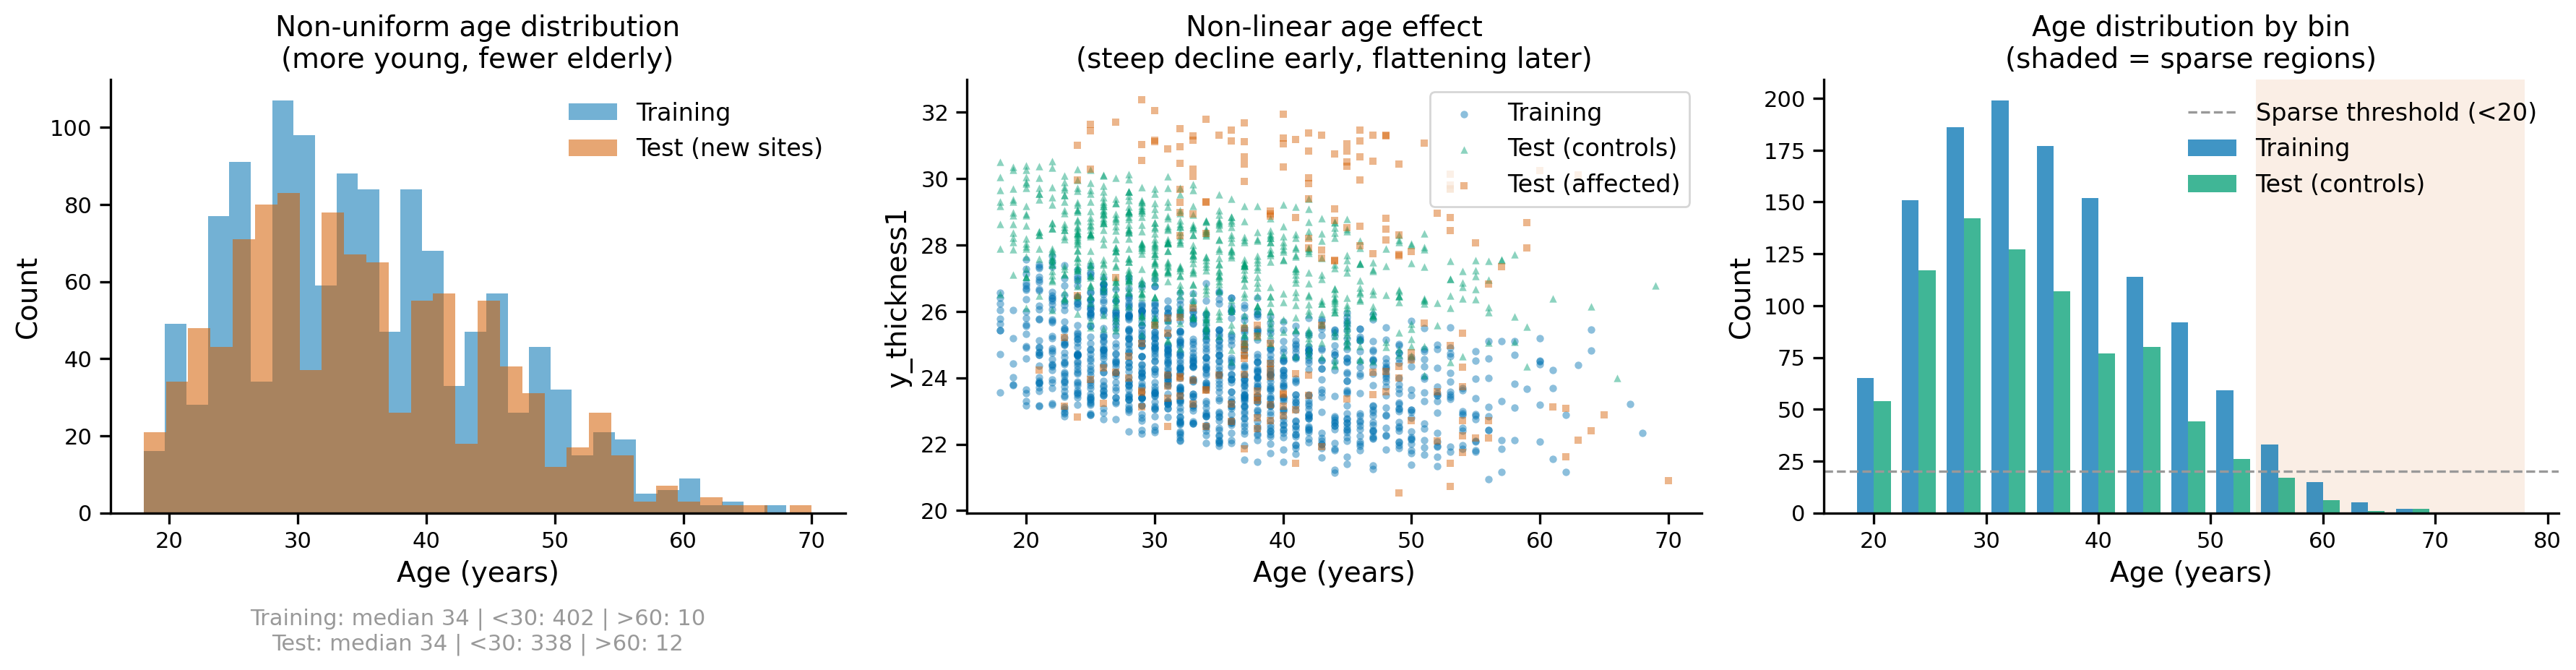


✓ Data visualization saved

Key Characteristics:
  - Age distribution is SKEWED (more young, fewer elderly)
  - Non-linear effects are STRONGER at age extremes
  - Elderly samples (>60) are SPARSE: 12 samples
  - This makes sampling strategy CRITICAL for model transfer


In [95]:
# ============================================================================
# Visualize Age Distributions
# ============================================================================

print("\n" + "="*70)
print("AGE DISTRIBUTION ANALYSIS")
print("="*70)

from normgamlss.plot_style import (
    apply_publication_style, BLUE, VERMILION, GREEN, GREY,
)
apply_publication_style()

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Plot 1: Age histograms
axes[0].hist(train_data['age'], bins=30, alpha=0.55, label='Training',
             color=BLUE, linewidth=0)
axes[0].hist(test_data1['age'], bins=30, alpha=0.55, label='Test (new sites)',
             color=VERMILION, linewidth=0)
axes[0].set_xlabel('Age (years)', fontsize=14)
axes[0].set_ylabel('Count', fontsize=14)
axes[0].set_title('Non-uniform age distribution\n(more young, fewer elderly)', fontsize=14)
axes[0].legend(fontsize=12, frameon=False)

# Age distribution stats, as a caption under the panel (not a boxed overlay)
age_train_median = np.median(train_data['age'])
age_test_median = np.median(test_data1['age'])
stats_text = (f"Training: median {age_train_median:.0f} | "
              f"<30: {(train_data['age']<30).sum()} | "
              f">60: {(train_data['age']>60).sum()}\n"
              f"Test: median {age_test_median:.0f} | "
              f"<30: {(test_data1['age']<30).sum()} | "
              f">60: {(test_data1['age']>60).sum()}")
axes[0].annotate(stats_text, xy=(0.5, -0.22), xycoords='axes fraction',
                 ha='center', va='top', fontsize=11, color=GREY)

# Plot 2: Age vs y_thickness showing non-linearity
for dataset, label, color, marker in [
    (train_data, 'Training', BLUE, 'o'),
    (test_data1[test_data1['affected'] == 'None'], 'Test (controls)', GREEN, '^'),
    (test_data1[test_data1['affected'] != 'None'], 'Test (affected)', VERMILION, 's'),
]:
    axes[1].scatter(dataset['age'], dataset['y_thickness1'],
                    alpha=0.45, s=14, label=label, color=color, marker=marker,
                    linewidths=0)

axes[1].set_xlabel('Age (years)', fontsize=14)
axes[1].set_ylabel('y_thickness1', fontsize=14)
axes[1].set_title('Non-linear age effect\n(steep decline early, flattening later)', fontsize=14)
axes[1].legend(fontsize=12, frameon=True)

# Plot 3: Show the age "sparsity" issue
age_bins = np.arange(18, 82, 4)
train_counts, _ = np.histogram(train_data['age'], bins=age_bins)
test_counts, _ = np.histogram(test_data1[test_data1['affected'] == 'None']['age'], bins=age_bins)

x_pos = age_bins[:-1] + 2
width = 1.5

axes[2].bar(x_pos - width/2, train_counts, width, label='Training',
            color=BLUE, alpha=0.75, linewidth=0)
axes[2].bar(x_pos + width/2, test_counts, width, label='Test (controls)',
            color=GREEN, alpha=0.75, linewidth=0)

# Highlight sparse regions
sparse_threshold = 20
for i, test_c in enumerate(test_counts):
    if test_c < sparse_threshold:
        axes[2].axvspan(age_bins[i], age_bins[i+1], alpha=0.10, color=VERMILION,
                        linewidth=0, zorder=0)

axes[2].axhline(sparse_threshold, color=GREY, linestyle='--', linewidth=1.2,
                label=f'Sparse threshold (<{sparse_threshold})')
axes[2].set_xlabel('Age (years)', fontsize=14)
axes[2].set_ylabel('Count', fontsize=14)
axes[2].set_title('Age distribution by bin\n(shaded = sparse regions)', fontsize=14)
axes[2].legend(fontsize=12, frameon=False, loc='upper right')

fig.tight_layout()
plt.savefig('../../results/nonlinear_nonuniform_data.png', dpi=300, bbox_inches='tight')
plt.show()

print("\n✓ Data visualization saved")
print(f"\nKey Characteristics:")
print(f"  - Age distribution is SKEWED (more young, fewer elderly)")
print(f"  - Non-linear effects are STRONGER at age extremes")
print(f"  - Elderly samples (>60) are SPARSE: {(test_data1['age']>60).sum()} samples")
print(f"  - This makes sampling strategy CRITICAL for model transfer")

In [96]:

# ============================================================================
# SECTION 2: COMPARE SAMPLING STRATEGIES WITH PROPER VISUALIZATION
# ============================================================================

print("\n\n" + "="*70)
print("SECTION 2: SAMPLING STRATEGY COMPARISON")
print("="*70)

# Select one new site for demonstration
demo_site = new_sites[0]
demo_site_data = test_data1[test_data1['site'] == demo_site].copy()

# Filter for healthy subjects
healthy_demo = demo_site_data[demo_site_data['affected'] == 'None'].copy()
fraction = 0.2

print(f"\nDemonstration site: {demo_site}")
print(f"  Total samples: {len(demo_site_data)}")
print(f"  Healthy samples: {len(healthy_demo)}")
print(f"  Sampling fraction: {fraction} ({int(len(healthy_demo) * fraction)} samples)")
print(f"  Age distribution:")
print(f"    - 18-30: {((healthy_demo['age']>=18) & (healthy_demo['age']<30)).sum()} samples")
print(f"    - 30-45: {((healthy_demo['age']>=30) & (healthy_demo['age']<45)).sum()} samples")
print(f"    - 45-60: {((healthy_demo['age']>=45) & (healthy_demo['age']<60)).sum()} samples")
print(f"    - 60-80: {((healthy_demo['age']>=60) & (healthy_demo['age']<=80)).sum()} samples")

# ============================================================================
# Apply Different Sampling Strategies
# ============================================================================

print("\n" + "-"*70)
print("Applying sampling strategies...")
print("-"*70)

from normgamlss.site_transfer_utils import (
    random_sampling,
    stratified_age_sampling,
    uniform_age_sampling
)

# 1. Random sampling
sampled_random = random_sampling(healthy_demo, fraction, random_state=42)
print(f"✓ Random sampling: {len(sampled_random)} samples")

# 2. Stratified age sampling
sampled_stratified = stratified_age_sampling(
    healthy_demo, 
    fraction, 
    age_col='age', 
    n_bins=10, 
    random_state=42
)
print(f"✓ Stratified age sampling: {len(sampled_stratified)} samples")

# 3. Uniform age sampling
sampled_uniform = uniform_age_sampling(
    healthy_demo,
    fraction,
    age_col='age',
    jitter_range=2,
    random_state=42
)
print(f"✓ Uniform age sampling: {len(sampled_uniform)} samples")




SECTION 2: SAMPLING STRATEGY COMPARISON

Demonstration site: ZSCPY
  Total samples: 250
  Healthy samples: 199
  Sampling fraction: 0.2 (39 samples)
  Age distribution:
    - 18-30: 73 samples
    - 30-45: 97 samples
    - 45-60: 28 samples
    - 60-80: 1 samples

----------------------------------------------------------------------
Applying sampling strategies...
----------------------------------------------------------------------
✓ Random sampling: 39 samples
✓ Stratified age sampling: 39 samples
✓ Uniform age sampling: 39 samples


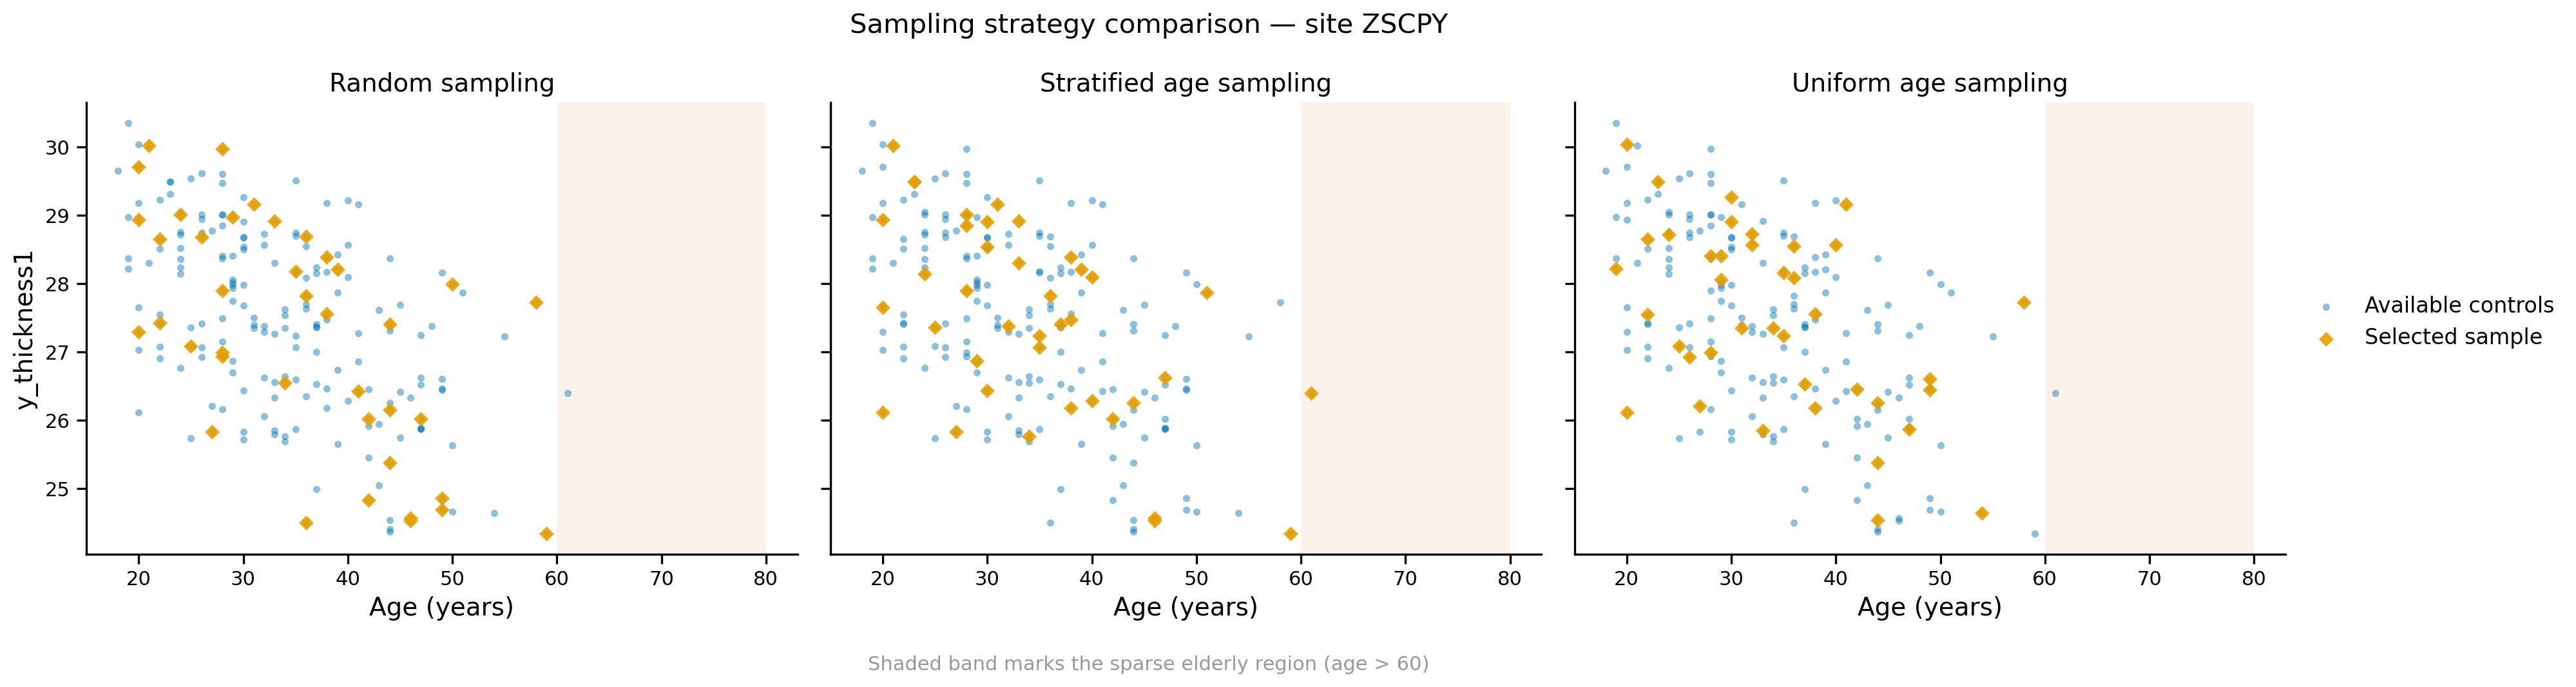


✓ Main comparison saved to: ../../results/sampling_strategy_comparison_main.png

Strategy                     Total              Age<30     Age 30-60    Age>60     Elderly
--------------------------------------------------------------------------------------------
Random sampling              39/199 (19.6%)     15/73      24/125       0/1        MISSED
Stratified age sampling      39/199 (19.6%)     13/73      25/125       1/1        ok
Uniform age sampling         39/199 (19.6%)     14/73      25/125       0/1        MISSED


In [97]:
from normgamlss.plot_style import (
    apply_publication_style, BLUE, ORANGE, VERMILION, GREY,
)
apply_publication_style()

fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharex=True, sharey=True)

strategies = [
    ('Random sampling', sampled_random),
    ('Stratified age sampling', sampled_stratified),
    ('Uniform age sampling', sampled_uniform)
]

coverage_rows = []

for idx, (strategy_name, sampled_data) in enumerate(strategies):
    ax = axes[idx]

    # Sparse elderly region, drawn first so it sits behind the points
    ax.axvspan(60, 80, alpha=0.08, color=VERMILION, linewidth=0, zorder=0)

    # All available control samples (background layer)
    ax.scatter(healthy_demo['age'], healthy_demo['y_thickness1'],
               alpha=0.45, s=16, color=BLUE, linewidths=0, zorder=3,
               label='Available controls')

    # The subset this strategy selected (foreground layer)
    ax.scatter(sampled_data['age'], sampled_data['y_thickness1'],
               alpha=0.9, s=34, color=ORANGE, marker='D', linewidths=0, zorder=4,
               label='Selected sample')

    ax.set_xlabel('Age (years)', fontsize=14)
    if idx == 0:
        ax.set_ylabel('y_thickness1', fontsize=14)
    ax.set_title(strategy_name, fontsize=14)
    ax.set_xlim(15, 83)

    # Coverage numbers go in the printed table below, not on top of the data
    elderly_all = healthy_demo[healthy_demo['age'] > 60]
    elderly_sampled = sampled_data[sampled_data['age'] > 60]
    coverage_rows.append((
        strategy_name,
        f"{len(sampled_data)}/{len(healthy_demo)} ({len(sampled_data)/len(healthy_demo)*100:.1f}%)",
        f"{len(sampled_data[sampled_data['age']<30])}/{len(healthy_demo[healthy_demo['age']<30])}",
        f"{len(sampled_data[(sampled_data['age']>=30)&(sampled_data['age']<=60)])}/{len(healthy_demo[(healthy_demo['age']>=30)&(healthy_demo['age']<=60)])}",
        f"{len(elderly_sampled)}/{len(elderly_all)}",
        # "good" = captured at least 2, or all of them when fewer than 2 exist
        'ok' if len(elderly_sampled) >= min(2, len(elderly_all)) else 'MISSED',
    ))

# One shared legend for all three panels, outside the axes
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='center left', bbox_to_anchor=(0.99, 0.5),
           fontsize=12, frameon=False)
fig.suptitle(f'Sampling strategy comparison — site {demo_site}', fontsize=15)
fig.text(0.5, -0.04, 'Shaded band marks the sparse elderly region (age > 60)',
         ha='center', fontsize=11, color=GREY)
fig.tight_layout()
plt.savefig('../../results/sampling_strategy_comparison_main.png', dpi=300, bbox_inches='tight')
plt.show()

print("\n✓ Main comparison saved to: ../../results/sampling_strategy_comparison_main.png")

print(f"\n{'Strategy':<28} {'Total':<18} {'Age<30':<10} {'Age 30-60':<12} {'Age>60':<10} {'Elderly'}")
print("-" * 92)
for name, total, young, mid, old, status in coverage_rows:
    print(f"{name:<28} {total:<18} {young:<10} {mid:<12} {old:<10} {status}")

### Running the main model
We will be using this model as our base model, utilized to be finetuned our data from new sites to be transferred

In [98]:
print("\n" + "="*80)
print("SECTION 3: FITTING MAIN GAMLSS MODEL")
print("="*80)

y_val = 'y_thickness1'
x_vals = ['age', 'sex', 'site']
columns = x_vals + [y_val]
train_data1 = train_data.loc[:, columns]

model_name = 'main_model_nonlinear'
gamlss_model = Gamlss(model_name, x_vals, y_val)

print("\n⚙️  Fitting GAMLSS model with non-linear age effects...")
print("   Formula: y ~ pvc(age, by=sex) + random(site)")
print("   Distribution: SHASH")
print("   Method: RS(100)")

gamlss_model.fit(
    r_code="""
    model <- gamlss(y ~ pvc(age, by = as.factor(sex)) + re(random=~1|site),
        sigma.formula = ~ pvc(age) + re(random=~1|site),
        nu.formula = ~ 1,
        tau.formula = ~ 1,
        family = SHASH(),
        method = RS(100)
    )
    """,
    data=train_data1
)

main_model_path = "../../results/site_transfer_main_model_nonlinear.rds"
gamlss_model.save_model(main_model_path)
print(f"\n✓ Main model saved to: {main_model_path}")


SECTION 3: FITTING MAIN GAMLSS MODEL

⚙️  Fitting GAMLSS model with non-linear age effects...
   Formula: y ~ pvc(age, by=sex) + random(site)
   Distribution: SHASH
   Method: RS(100)
GAMLSS-RS iteration 1: Global Deviance = 4300.439 
GAMLSS-RS iteration 2: Global Deviance = 4209.972 
GAMLSS-RS iteration 3: Global Deviance = 4142.562 
GAMLSS-RS iteration 4: Global Deviance = 4090.598 
GAMLSS-RS iteration 5: Global Deviance = 4048.285 
GAMLSS-RS iteration 6: Global Deviance = 4015.729 
GAMLSS-RS iteration 7: Global Deviance = 3989.021 
GAMLSS-RS iteration 8: Global Deviance = 3966.876 
GAMLSS-RS iteration 9: Global Deviance = 3948.126 
GAMLSS-RS iteration 10: Global Deviance = 3931.993 
GAMLSS-RS iteration 11: Global Deviance = 3918.267 
GAMLSS-RS iteration 12: Global Deviance = 3906.406 
GAMLSS-RS iteration 13: Global Deviance = 3895.896 
GAMLSS-RS iteration 14: Global Deviance = 3886.746 
GAMLSS-RS iteration 15: Global Deviance = 3878.64 
GAMLSS-RS iteration 16: Global Deviance = 387

In [99]:
# ============================================================================
# SECTION 4: MULTISITE TRANSFER WITH STRATIFIED SAMPLING
# ============================================================================

print("\n\n" + "="*80)
print("SECTION 4: MULTISITE TRANSFER WITH STRATIFIED AGE SAMPLING")
print("="*80)

new_sites_list = list(new_sites)
selected_sites = train_sites[0]  # Use first training site as proxy
fractions = 0.2
iterations = 50

save_folder = "../../results/site_transfer_results_nonlinear"
file_name = "multi_site_transfer_results.pkl"

print(f"\n📋 Transfer Configuration:")
print(f"  New sites: {new_sites_list}")
print(f"  Proxy site: {selected_sites}")
print(f"  Fraction: {fractions} (20% of healthy samples)")
print(f"  Sampling strategy: stratified_age ✓")
print(f"  Age bins: 10")
print(f"  Iterations: {iterations}")

print(f"\n🚀 Starting multisite transfer...")

results = multisite_transfer(
    main_model_path=main_model_path,
    main_traindata=train_data1,
    df2=test_data1,
    new_sites=new_sites_list,
    selected_sites=selected_sites,
    sample_sizes=fractions,
    y_val=y_val,
    x_vals=x_vals,
    iterations=iterations,
    save_folder=save_folder,
    file_name=file_name,
    sampling_strategy='stratified_age',
    sampling_params={
        'age_col': 'age',
        'n_bins': 10,
        'random_state': 42
    }
)

print("\n✓ Transfer completed successfully!")
print(f"✓ Results saved to: {save_folder}")



SECTION 4: MULTISITE TRANSFER WITH STRATIFIED AGE SAMPLING

📋 Transfer Configuration:
  New sites: ['ZSCPY', 'KEMUB', 'HLMEG', 'OTLIE']
  Proxy site: ESZYC
  Fraction: 0.2 (20% of healthy samples)
  Sampling strategy: stratified_age ✓
  Age bins: 10
  Iterations: 50

🚀 Starting multisite transfer...
Adjustment models will be saved to: ../../results/site_transfer_results_nonlinear/adjustment_models
Sampling strategy: stratified_age
Sampling parameters: {'age_col': 'age', 'n_bins': 10, 'random_state': 42}



Processing sites:   0%|          | 0/4 [00:00<?, ?it/s]


Processing: ZSCPY (proxy: ESZYC, sample_size: 0.2)
Model 'main_model_nonlinear_2' loaded from ../../results/site_transfer_main_model_nonlinear.rds
No 'affected' array provided. Using 'affected' column from data.
Using 199 healthy subjects out of 250 total subjects
Site: ZSCPY | Strategy: stratified_age
  Total samples:                   250
  Healthy samples:                 199
  Training samples for adjustment: 39
  Age range in sample:             [20.0, 61.0]

Creating adjustment model: gam_refit_ZSCPY_20
  Adjusting parameters: ['mu', 'sigma', 'nu', 'tau']
GAMLSS-RS iteration 1: Global Deviance = 131.674 
GAMLSS-RS iteration 2: Global Deviance = 129.4122 
GAMLSS-RS iteration 3: Global Deviance = 127.6862 
GAMLSS-RS iteration 4: Global Deviance = 126.3407 
GAMLSS-RS iteration 5: Global Deviance = 125.3458 
GAMLSS-RS iteration 6: Global Deviance = 124.4801 
GAMLSS-RS iteration 7: Global Deviance = 123.8206 
GAMLSS-RS iteration 8: Global Deviance = 123.2847 
GAMLSS-RS iteration 9: G

normgamlss/site_transfer_utils.py:1264: RuntimeWarning: site_transfer [ZSCPY]: adjustment model did not converge in 50 RS cycles (n=39, params=['mu', 'sigma', 'nu', 'tau']). Adjustment intercepts are unreliable; raise `iterations` or exclude this cell.
  warnings.warn(
Processing sites:  25%|██▌       | 1/4 [00:02<00:06,  2.29s/it]


Processing: KEMUB (proxy: ESZYC, sample_size: 0.2)
Model 'main_model_nonlinear_2' loaded from ../../results/site_transfer_main_model_nonlinear.rds
No 'affected' array provided. Using 'affected' column from data.
Using 197 healthy subjects out of 250 total subjects
Site: KEMUB | Strategy: stratified_age
  Total samples:                   250
  Healthy samples:                 197
  Training samples for adjustment: 39
  Age range in sample:             [20.0, 53.0]

Creating adjustment model: gam_refit_KEMUB_20
  Adjusting parameters: ['mu', 'sigma', 'nu', 'tau']
GAMLSS-RS iteration 1: Global Deviance = 139.6973 
GAMLSS-RS iteration 2: Global Deviance = 136.1457 
GAMLSS-RS iteration 3: Global Deviance = 134.1787 
GAMLSS-RS iteration 4: Global Deviance = 132.609 
GAMLSS-RS iteration 5: Global Deviance = 131.3298 
GAMLSS-RS iteration 6: Global Deviance = 130.2579 
GAMLSS-RS iteration 7: Global Deviance = 129.3658 
GAMLSS-RS iteration 8: Global Deviance = 128.6184 
GAMLSS-RS iteration 9: G

...


Processing: HLMEG (proxy: ESZYC, sample_size: 0.2)
Model 'main_model_nonlinear_2' loaded from ../../results/site_transfer_main_model_nonlinear.rds
No 'affected' array provided. Using 'affected' column from data.
Using 206 healthy subjects out of 250 total subjects
Site: HLMEG | Strategy: stratified_age
  Total samples:                   250
  Healthy samples:                 206
  Training samples for adjustment: 41
  Age range in sample:             [22.0, 53.0]

Creating adjustment model: gam_refit_HLMEG_20
  Adjusting parameters: ['mu', 'sigma', 'nu', 'tau']
GAMLSS-RS iteration 1: Global Deviance = 150.9196 
GAMLSS-RS iteration 2: Global Deviance = 147.2778 
GAMLSS-RS iteration 3: Global Deviance = 144.601 
GAMLSS-RS iteration 4: Global Deviance = 142.549 
GAMLSS-RS iteration 5: Global Deviance = 141.0611 
GAMLSS-RS iteration 6: Global Deviance = 139.8688 
GAMLSS-RS iteration 7: Global Deviance = 138.8872 
GAMLSS-RS iteration 8: Global Deviance = 138.067 
GAMLSS-RS iteration 9: Glo

normgamlss/site_transfer_utils.py:1264: RuntimeWarning: site_transfer [HLMEG]: adjustment model did not converge in 50 RS cycles (n=41, params=['mu', 'sigma', 'nu', 'tau']). Adjustment intercepts are unreliable; raise `iterations` or exclude this cell.
  warnings.warn(
Processing sites:  75%|███████▌  | 3/4 [00:06<00:02,  2.28s/it]


Processing: OTLIE (proxy: ESZYC, sample_size: 0.2)
Model 'main_model_nonlinear_2' loaded from ../../results/site_transfer_main_model_nonlinear.rds
No 'affected' array provided. Using 'affected' column from data.
Using 198 healthy subjects out of 250 total subjects
Site: OTLIE | Strategy: stratified_age
  Total samples:                   250
  Healthy samples:                 198
  Training samples for adjustment: 39
  Age range in sample:             [19.0, 55.0]

Creating adjustment model: gam_refit_OTLIE_20
  Adjusting parameters: ['mu', 'sigma', 'nu', 'tau']
GAMLSS-RS iteration 1: Global Deviance = 106.9128 
GAMLSS-RS iteration 2: Global Deviance = 105.5404 
GAMLSS-RS iteration 3: Global Deviance = 104.5896 
GAMLSS-RS iteration 4: Global Deviance = 103.9158 
GAMLSS-RS iteration 5: Global Deviance = 103.3804 
GAMLSS-RS iteration 6: Global Deviance = 103.0319 
GAMLSS-RS iteration 7: Global Deviance = 102.7705 
GAMLSS-RS iteration 8: Global Deviance = 102.5633 
GAMLSS-RS iteration 9: 

Processing sites: 100%|██████████| 4/4 [00:08<00:00,  2.23s/it]


✓ Results dictionary saved to: ../../results/site_transfer_results_nonlinear/multi_site_transfer_results.pkl

✓ Transfer completed successfully!
✓ Results saved to: ../../results/site_transfer_results_nonlinear


In [100]:
# ============================================================================
# SECTION 5: RESULTS SUMMARY
# ============================================================================

print("\n\n" + "="*80)
print("SECTION 5: TRANSFER RESULTS SUMMARY")
print("="*80)

print(f"\n✓ Sites processed: {list(results.keys())}")

print(f"\n{'Site':<10} {'Samples Used':<15} {'Proxy':<10} {'Strategy':<25} {'Model Path'}")
print("-"*100)
for site in results.keys():
    print(f"{site:<10} "
          f"{len(results[site]['train_set_index']):<15} "
          f"{results[site]['selected_site']:<10} "
          f"{results[site]['sampling_strategy']:<25} "
          f"{results[site]['gam_refit_model_path'].split('/')[-1]}")



SECTION 5: TRANSFER RESULTS SUMMARY

✓ Sites processed: ['ZSCPY', 'KEMUB', 'HLMEG', 'OTLIE']

Site       Samples Used    Proxy      Strategy                  Model Path
----------------------------------------------------------------------------------------------------
ZSCPY      39              ESZYC      stratified_age            gam_refit_ZSCPY_20.rds
KEMUB      39              ESZYC      stratified_age            gam_refit_KEMUB_20.rds
HLMEG      41              ESZYC      stratified_age            gam_refit_HLMEG_20.rds
OTLIE      39              ESZYC      stratified_age            gam_refit_OTLIE_20.rds


In [101]:
# ============================================================================
# Detailed Analysis for One Site
# ============================================================================

exp_site = new_sites_list[0]
exp_results = results[exp_site]

print(f"\n" + "-"*80)
print(f"📊 Detailed Analysis: {exp_site}")
print("-"*80)

adjustment_effect = (exp_results['adjusted_predictions']['mu_pred'].mean() - 
                     exp_results['unadjusted_predictions']['mu_pred'].mean())
test_site_df = test_data1[test_data1['site'] == exp_site]
actual_mean = test_site_df['y_thickness1'].mean()

print(f"\nPrediction Adjustment:")
print(f"  Unadjusted mean: {exp_results['unadjusted_predictions']['mu_pred'].mean():.3f}")
print(f"  Adjusted mean: {exp_results['adjusted_predictions']['mu_pred'].mean():.3f}")
print(f"  Adjustment effect: {adjustment_effect:+.3f}")
print(f"  Actual data mean: {actual_mean:.3f}")
print(f"  Error reduction: {abs(exp_results['unadjusted_predictions']['mu_pred'].mean() - actual_mean):.3f} → "
      f"{abs(exp_results['adjusted_predictions']['mu_pred'].mean() - actual_mean):.3f}")


--------------------------------------------------------------------------------
📊 Detailed Analysis: ZSCPY
--------------------------------------------------------------------------------

Prediction Adjustment:
  Unadjusted mean: 24.157
  Adjusted mean: 27.410
  Adjustment effect: +3.253
  Actual data mean: 27.154
  Error reduction: 2.997 → 0.255


#### Verifying if the predictions has been adjusted or not
Please observe the mu value as while creating the data we set it to high and there we can see the change

In [102]:
results

{'ZSCPY': {'unadjusted_predictions':        mu_pred  sigma_pred   nu_pred  tau_pred
  1    23.395484    3.742806  2.914168   2.63606
  2    23.701611    3.738236  2.914168   2.63606
  3    23.574131    3.729085  2.914168   2.63606
  4    24.837949    3.774848  2.914168   2.63606
  5    24.033636    3.751941  2.914168   2.63606
  ..         ...         ...       ...       ...
  246  24.752682    3.772547  2.914168   2.63606
  247  24.616851    3.786394  2.914168   2.63606
  248  23.124384    3.729085  2.914168   2.63606
  249  24.249009    3.774848  2.914168   2.63606
  250  23.965309    3.749657  2.914168   2.63606
  
  [250 rows x 4 columns],
  'adjusted_predictions':        mu_pred  sigma_pred   nu_pred  tau_pred
  1    26.648371    2.045084  1.499968  1.713603
  2    26.954498    2.042587  1.499968  1.713603
  3    26.827018    2.037587  1.499968  1.713603
  4    28.090835    2.062592  1.499968  1.713603
  5    27.286523    2.050075  1.499968  1.713603
  ..         ...         ...  

In [103]:
results

{'ZSCPY': {'unadjusted_predictions':        mu_pred  sigma_pred   nu_pred  tau_pred
  1    23.395484    3.742806  2.914168   2.63606
  2    23.701611    3.738236  2.914168   2.63606
  3    23.574131    3.729085  2.914168   2.63606
  4    24.837949    3.774848  2.914168   2.63606
  5    24.033636    3.751941  2.914168   2.63606
  ..         ...         ...       ...       ...
  246  24.752682    3.772547  2.914168   2.63606
  247  24.616851    3.786394  2.914168   2.63606
  248  23.124384    3.729085  2.914168   2.63606
  249  24.249009    3.774848  2.914168   2.63606
  250  23.965309    3.749657  2.914168   2.63606
  
  [250 rows x 4 columns],
  'adjusted_predictions':        mu_pred  sigma_pred   nu_pred  tau_pred
  1    26.648371    2.045084  1.499968  1.713603
  2    26.954498    2.042587  1.499968  1.713603
  3    26.827018    2.037587  1.499968  1.713603
  4    28.090835    2.062592  1.499968  1.713603
  5    27.286523    2.050075  1.499968  1.713603
  ..         ...         ...  

In [104]:
# To access results for a specific site:
exp_site = 'ZSCPY'
exp_results = results[exp_site]
print(exp_results.keys())

dict_keys(['unadjusted_predictions', 'adjusted_predictions', 'z_scores', 'train_set_index', 'train_set_positions', 'z_scores_heldout', 'site_index', 'n_requested', 'n_realised', 'converged', 'selected_site', 'sample_size', 'sampling_strategy', 'sampling_params', 'params_to_adjust', 'adjustment_covariates', 'covariate_params', 'gam_refit_model_path'])


In [105]:
exp_results['unadjusted_predictions']

,mu_pred,sigma_pred,nu_pred,tau_pred
1,23.395484,3.742806,2.914168,2.63606
2,23.701611,3.738236,2.914168,2.63606
3,23.574131,3.729085,2.914168,2.63606
4,24.837949,3.774848,2.914168,2.63606
5,24.033636,3.751941,2.914168,2.63606
...,...,...,...,...
246,24.752682,3.772547,2.914168,2.63606
247,24.616851,3.786394,2.914168,2.63606
248,23.124384,3.729085,2.914168,2.63606
249,24.249009,3.774848,2.914168,2.63606


In [106]:
exp_results['adjusted_predictions']

,mu_pred,sigma_pred,nu_pred,tau_pred
1,26.648371,2.045084,1.499968,1.713603
2,26.954498,2.042587,1.499968,1.713603
3,26.827018,2.037587,1.499968,1.713603
4,28.090835,2.062592,1.499968,1.713603
5,27.286523,2.050075,1.499968,1.713603
...,...,...,...,...
246,28.005569,2.061335,1.499968,1.713603
247,27.869737,2.068901,1.499968,1.713603
248,26.377270,2.037587,1.499968,1.713603
249,27.501896,2.062592,1.499968,1.713603


In [107]:
exp_results

{'unadjusted_predictions':        mu_pred  sigma_pred   nu_pred  tau_pred
 1    23.395484    3.742806  2.914168   2.63606
 2    23.701611    3.738236  2.914168   2.63606
 3    23.574131    3.729085  2.914168   2.63606
 4    24.837949    3.774848  2.914168   2.63606
 5    24.033636    3.751941  2.914168   2.63606
 ..         ...         ...       ...       ...
 246  24.752682    3.772547  2.914168   2.63606
 247  24.616851    3.786394  2.914168   2.63606
 248  23.124384    3.729085  2.914168   2.63606
 249  24.249009    3.774848  2.914168   2.63606
 250  23.965309    3.749657  2.914168   2.63606
 
 [250 rows x 4 columns],
 'adjusted_predictions':        mu_pred  sigma_pred   nu_pred  tau_pred
 1    26.648371    2.045084  1.499968  1.713603
 2    26.954498    2.042587  1.499968  1.713603
 3    26.827018    2.037587  1.499968  1.713603
 4    28.090835    2.062592  1.499968  1.713603
 5    27.286523    2.050075  1.499968  1.713603
 ..         ...         ...       ...       ...
 246  28.00

In [108]:
# ============================================================================
# Step 1: Identify training samples used for adjustment
# ============================================================================

print(f"\n{'='*70}")
print(f"STEP 1: IDENTIFY TRAINING SAMPLES")
print(f"{'='*70}")

exp_site = new_sites_list[0]  # Using first site for demonstration
exp_results = results[exp_site]
proxy_site = exp_results['selected_site']

train_indices = exp_results['train_set_index']
print(f"\nSite being analyzed: {exp_site}")
print(f"Proxy site used: {proxy_site}")
print(f"Training samples used for adjustment: {len(train_indices)}")
print(f"Sampling strategy: {exp_results['sampling_strategy']}")



STEP 1: IDENTIFY TRAINING SAMPLES

Site being analyzed: ZSCPY
Proxy site used: ESZYC
Training samples used for adjustment: 39
Sampling strategy: stratified_age


#### ⚠️ Important: Filtering Training Samples

To avoid data leakage, we must exclude the samples that were used to train the adjustment model. These training samples were "seen" during model fitting and including them would give optimistically biased results. We filter to **holdout samples only** for unbiased evaluation.

### Compare Centiles Before and After Transfer

In [109]:
import matplotlib.pyplot as plt
from normgamlss.gamlss_main import Gamlss

# Load main model for plotting
main_model_nonlinear = Gamlss.load_model(main_model_path)

print(f"\n{'='*70}")
print(f"CENTILE COMPARISON: BEFORE vs AFTER TRANSFER")
print(f"{'='*70}\n")

# Prepare site data - GET FULL DATA FIRST
test_site_df_full = test_data1[test_data1['site'] == exp_site].copy()

# Filter to holdout samples only (exclude training samples used for adjustment)
train_indices = exp_results['train_set_index']
holdout_mask = ~test_site_df_full.index.isin(train_indices)
test_site_df = test_site_df_full[holdout_mask].copy()


proxy_site = exp_results['selected_site']  # Get the proxy site used for this transfer

print(f"Site: {exp_site}")
print(f"Proxy site used for transfer: {proxy_site}")
print()


Model 'main_model_nonlinear_2' loaded from ../../results/site_transfer_main_model_nonlinear.rds

CENTILE COMPARISON: BEFORE vs AFTER TRANSFER

Site: ZSCPY
Proxy site used for transfer: ESZYC



In [110]:
test_site_df.head()

,site,sex,age,feature_volume1,y_thickness1,affected
0,ZSCPY,0,43,858.446225,25.052316,None
1,ZSCPY,1,45,884.020233,25.747564,None
2,ZSCPY,1,49,975.158006,26.459649,None
3,ZSCPY,1,29,1023.264726,28.024935,None
4,ZSCPY,1,39,830.681660,22.701455,Dementia


**IMPORTANT NOTE**<br>
We need to change the site name of the `test_site_df` variable from above to the proxy site used in the main model because the test site does not exists in the main model training dataset and we have used the proxy site as the proxy for the test sites while adjusting

Generating BEFORE plot (no transfer adjustment)...
  - Using proxy site 'ESZYC' for centile curves
  - Showing actual data points from 'ZSCPY'
sex: mode = 1
site: mode = ESZYC
Figure saved to ../../results/site_transfer_results_nonlinear/centiles_ZSCPY_before.png


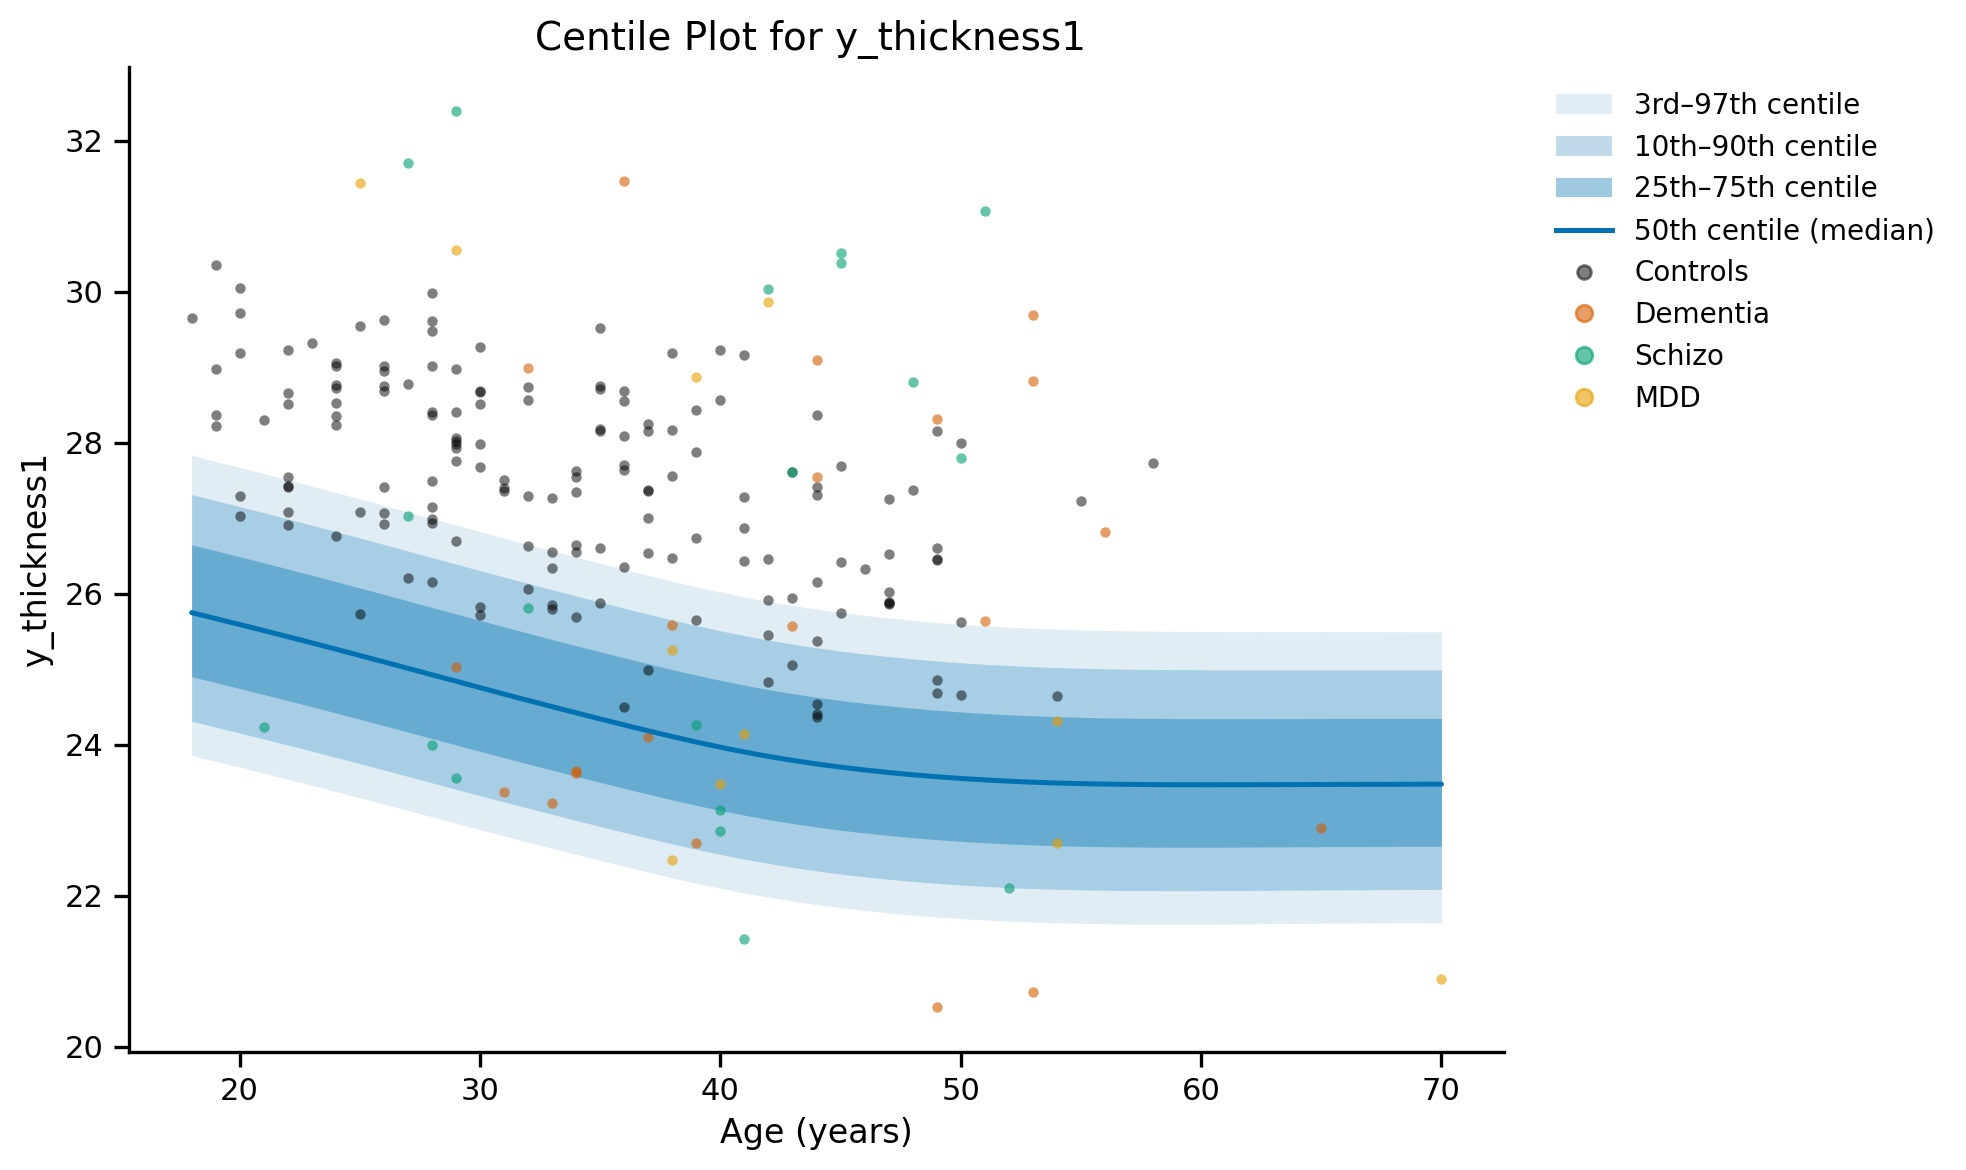


Values used for centile calculation in this plot:
sex: 1
site: ESZYC

Scatter data filtered by:
  No filtering applied (showing all scatter data)

Generating AFTER plot (with transfer adjustment)...
  - Using transfer-adjusted model for 'ZSCPY'
  - Showing actual data points from 'ZSCPY'
sex: mode = 1
site: mode = ESZYC
Model 'gam_refit_ZSCPY_20' loaded from ../../results/site_transfer_results_nonlinear/adjustment_models/gam_refit_ZSCPY_20.rds
Figure saved to ../../results/site_transfer_results_nonlinear/centiles_ZSCPY_after.png


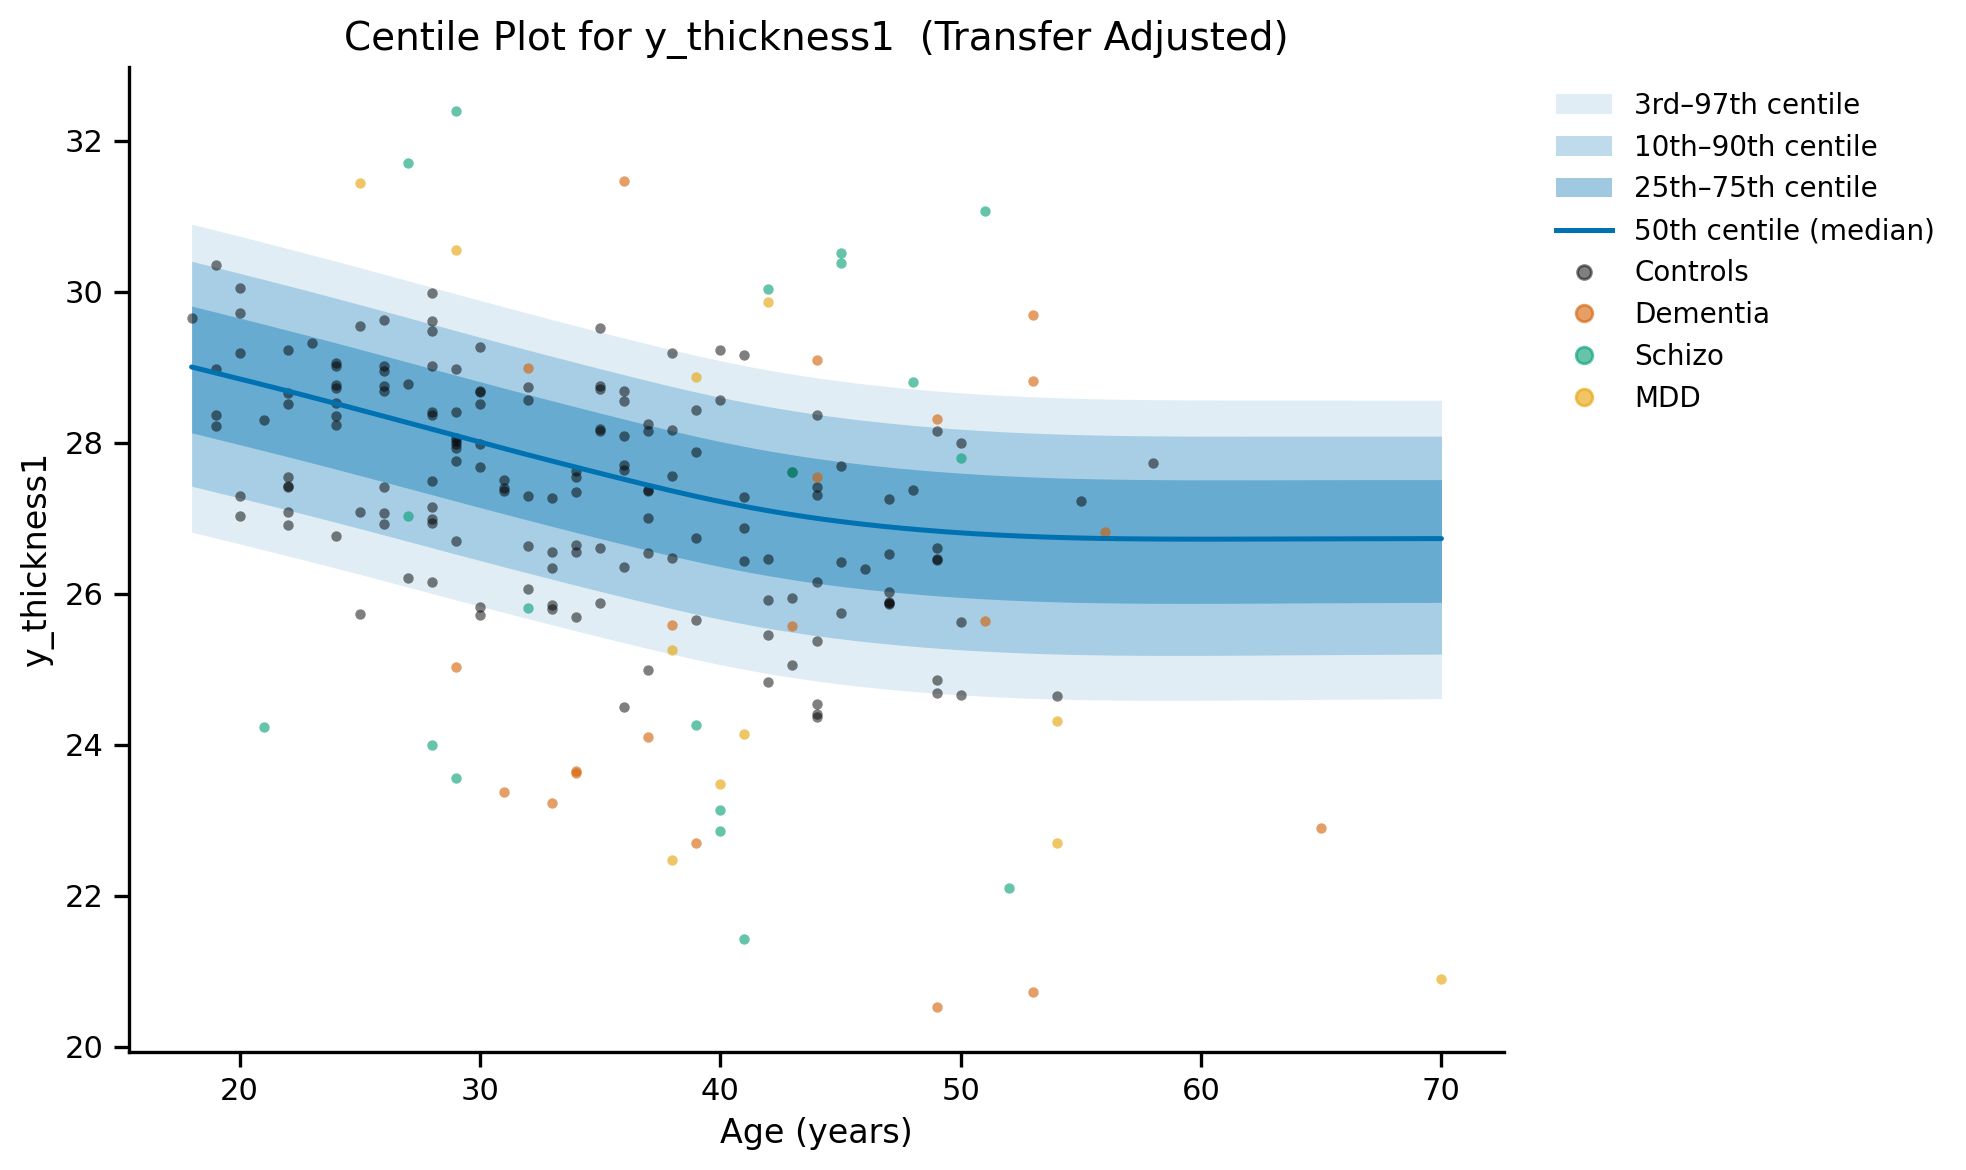


Values used for centile calculation in this plot:
sex: 1
site: ESZYC

Scatter data filtered by:
  No filtering applied (showing all scatter data)


In [111]:
# Changing the site name to proxy site as in the main model the test site does not exist
test_site_df_proxy = test_site_df.copy()
test_site_df_proxy['site'] = proxy_site


# Set up plot parameters
plot_params = {
    'centiles': [3, 10, 25, 50, 75, 90, 97],
    'affected': test_site_df_proxy['affected'],
    'x_axis': {'age': 'Age (years)'},
    'figsize': (10, 6),
    'font_size': [14, 12, 12, 10]
}

# BEFORE: Without transfer adjustment
# KEY FIX: Use additional_global_vars to specify proxy site for centile calculation
print(f"Generating BEFORE plot (no transfer adjustment)...")
print(f"  - Using proxy site '{proxy_site}' for centile curves")
print(f"  - Showing actual data points from '{exp_site}'")

main_model_nonlinear.plot_centiles(
    test_data=test_site_df_proxy,
    train_data=train_data1,
    use_transfer=False,  # ← No adjustment
    save_image=save_folder,
    file_name=f'centiles_{exp_site}_before.png',
    **plot_params
)

# AFTER: With transfer adjustment
print(f"\nGenerating AFTER plot (with transfer adjustment)...")
print(f"  - Using transfer-adjusted model for '{exp_site}'")
print(f"  - Showing actual data points from '{exp_site}'")

main_model_nonlinear.plot_centiles(
    test_data=test_site_df_proxy,
    train_data=train_data1,
    use_transfer=True,  # ← With adjustment
    gam_refit_path=exp_results['gam_refit_model_path'],
    save_image=save_folder,
    file_name=f'centiles_{exp_site}_after.png',
    **plot_params
);

### Compare Z-scores Before and After Transfer


Z-SCORE COMPARISON: BEFORE vs AFTER TRANSFER

Target site: ZSCPY
Proxy site: ESZYC
Samples: 211

[1/2] Generating z-score plot WITHOUT transfer adjustment...
      Using proxy site 'ESZYC' for z-score calculation
      Data points from 'ZSCPY'
Figure saved to ../../results/site_transfer_results_nonlinear/zscores_ZSCPY_before_scatter.png
Figure saved to ../../results/site_transfer_results_nonlinear/zscores_ZSCPY_before_distribution.png


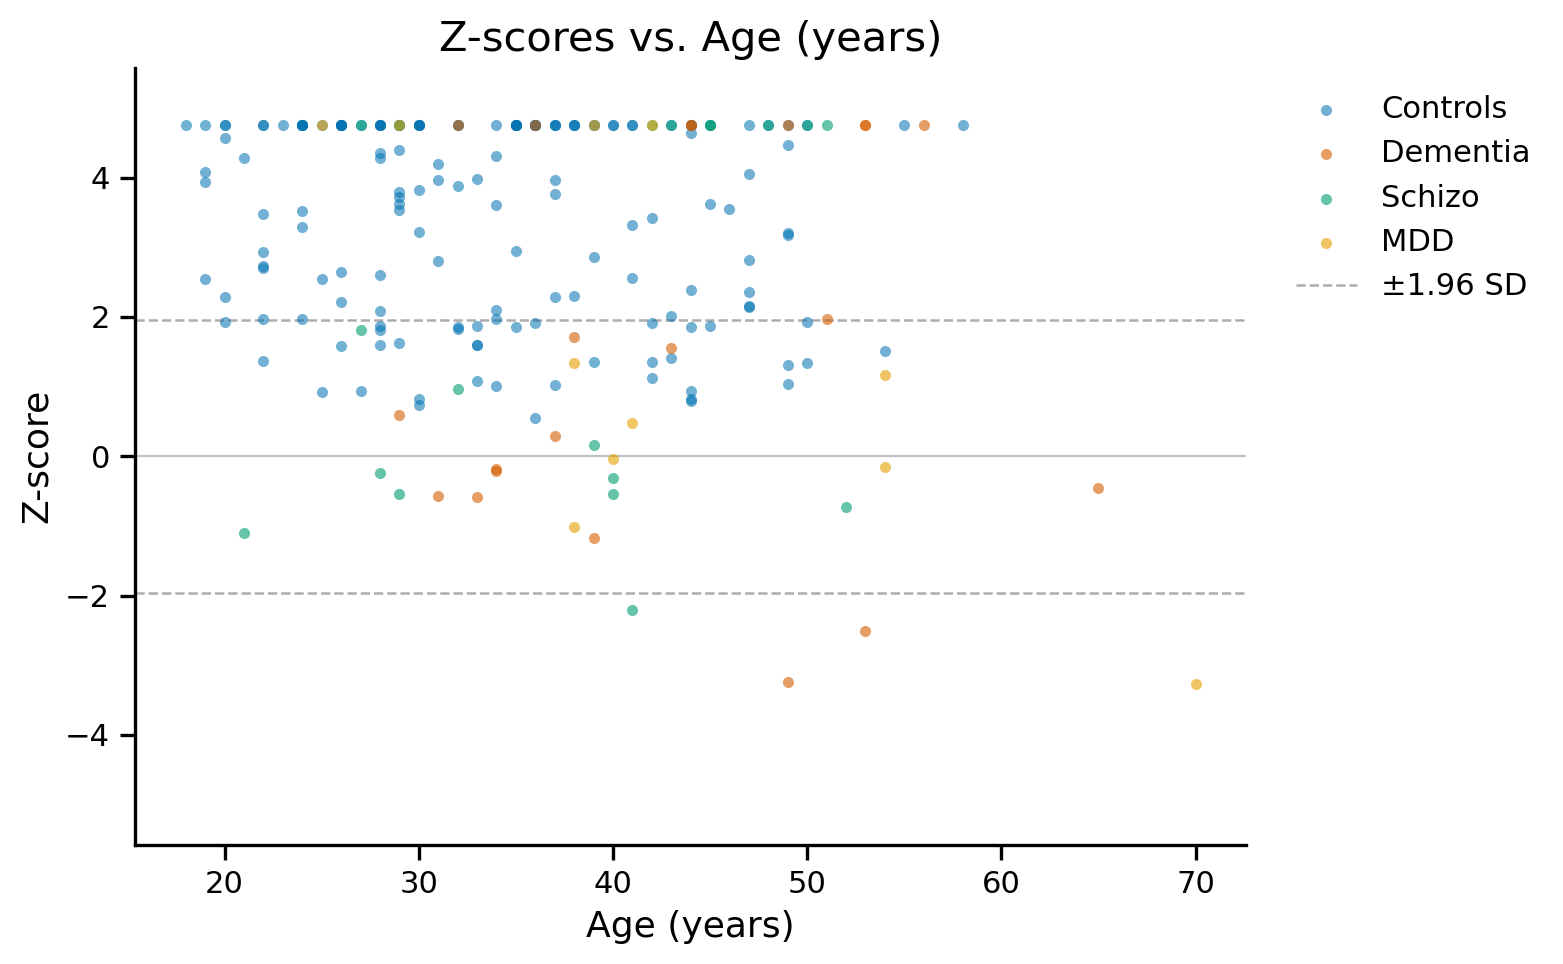

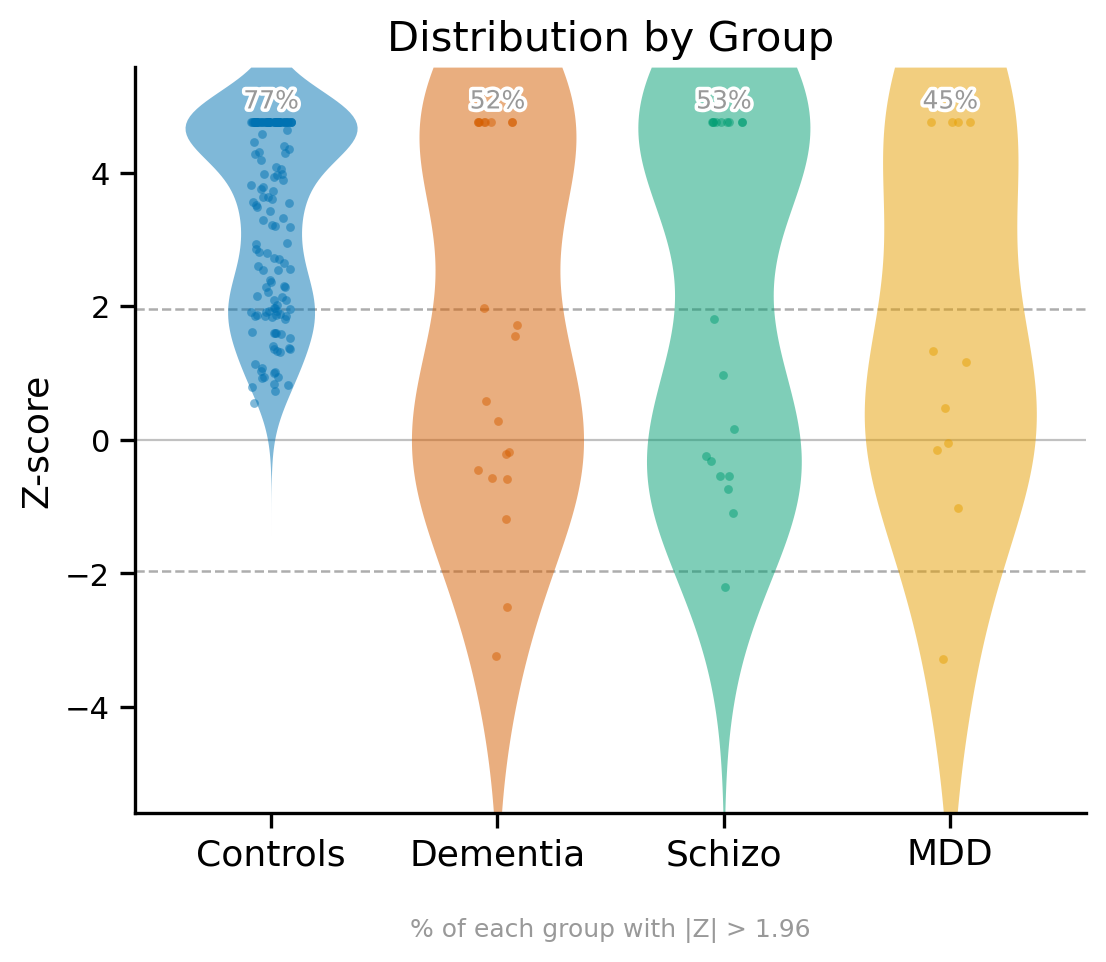


[2/2] Generating z-score plot WITH transfer adjustment...
      Using transfer-adjusted model for 'ZSCPY'
      Data points from 'ZSCPY'
Model 'gam_refit_ZSCPY_20' loaded from ../../results/site_transfer_results_nonlinear/adjustment_models/gam_refit_ZSCPY_20.rds
Figure saved to ../../results/site_transfer_results_nonlinear/zscores_ZSCPY_after_scatter.png
Figure saved to ../../results/site_transfer_results_nonlinear/zscores_ZSCPY_after_distribution.png


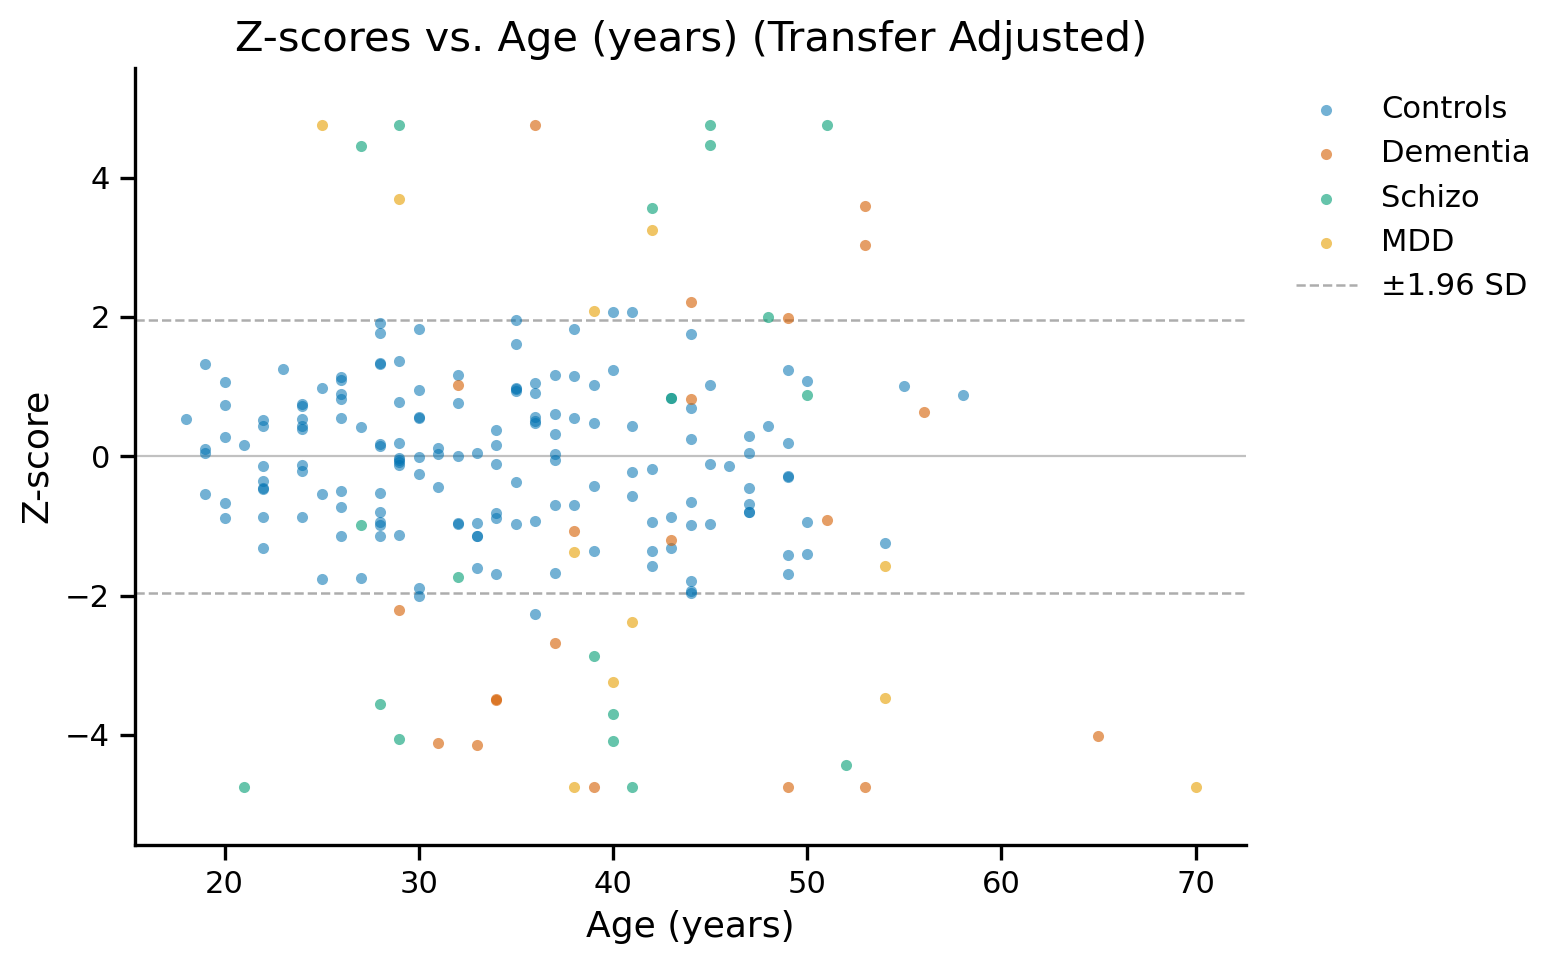

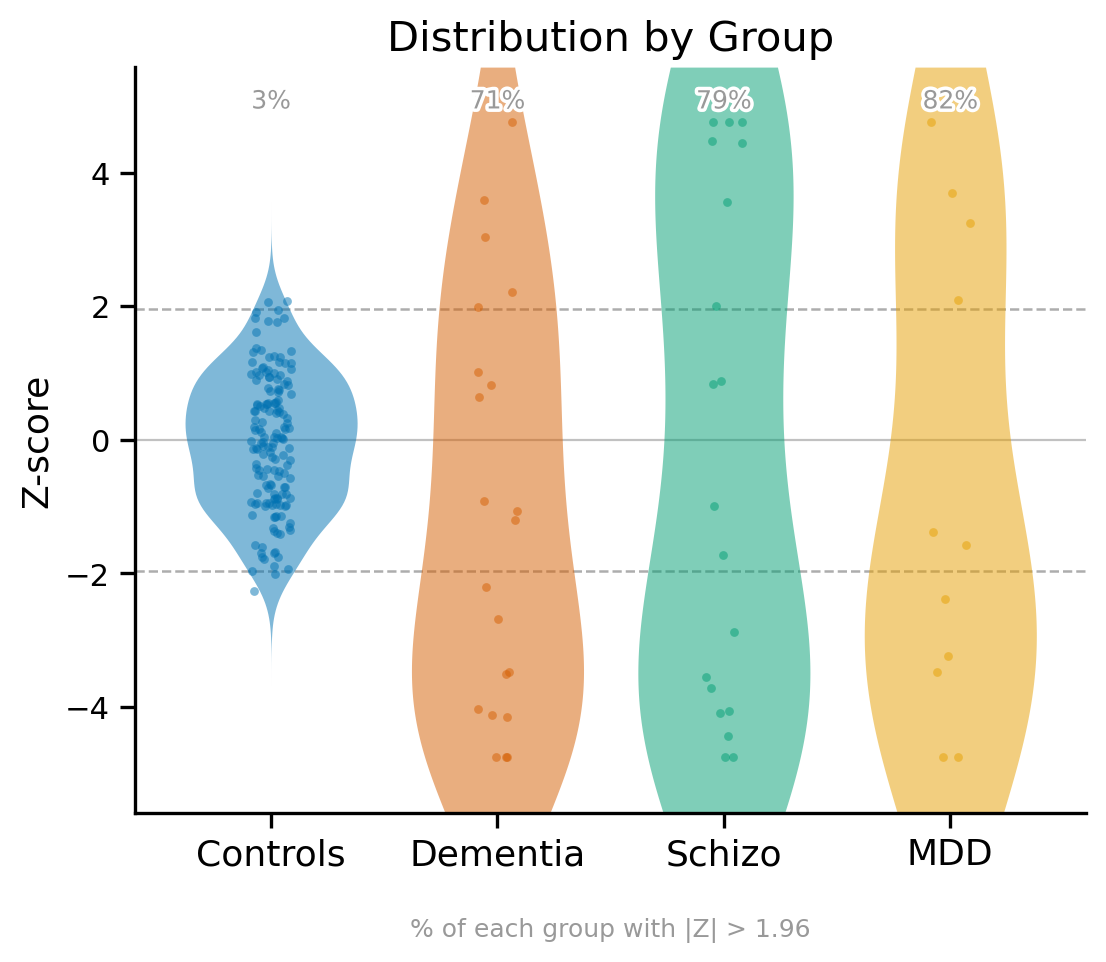

In [112]:
print(f"\n{'='*70}")
print(f"Z-SCORE COMPARISON: BEFORE vs AFTER TRANSFER")
print(f"{'='*70}\n")

# Prepare data - GET FULL DATA FIRST
test_site_df_full = test_data1[test_data1['site'] == exp_site].copy()

# Filter to holdout samples only
train_indices = exp_results['train_set_index']
holdout_mask = ~test_site_df_full.index.isin(train_indices)
test_site_df = test_site_df_full[holdout_mask].copy()

proxy_site = exp_results['selected_site']

# For BEFORE plot: use proxy site (like we did for centiles)
test_site_df_proxy = test_site_df.copy()
test_site_df_proxy['site'] = proxy_site

print(f"Target site: {exp_site}")
print(f"Proxy site: {proxy_site}")
print(f"Samples: {len(test_site_df)}")
print()

# BEFORE: Without transfer adjustment
print(f"[1/2] Generating z-score plot WITHOUT transfer adjustment...")
print(f"      Using proxy site '{proxy_site}' for z-score calculation")
print(f"      Data points from '{exp_site}'")

main_model_nonlinear.plot_z_scores(
    test_data=test_site_df_proxy,
    train_data=train_data1,
    affected=test_site_df_proxy['affected'],
    x_var='age',
    x_var_name='Age (years)',
    use_transfer=False,  # ← No adjustment
    save_image=save_folder,
    file_name=f'zscores_{exp_site}_before.png',
    font_size=[15, 13, 13, 11]
)

# AFTER: With transfer adjustment
print(f"\n[2/2] Generating z-score plot WITH transfer adjustment...")
print(f"      Using transfer-adjusted model for '{exp_site}'")
print(f"      Data points from '{exp_site}'")

main_model_nonlinear.plot_z_scores(
    test_data=test_site_df_proxy,
    train_data=train_data1,
    affected=test_site_df_proxy['affected'],
    x_var='age',
    x_var_name='Age (years)',
    use_transfer=True,  # ← With adjustment
    gam_refit_path=exp_results['gam_refit_model_path'],
    save_image=save_folder,
    file_name=f'zscores_{exp_site}_after.png',
    font_size=[15, 13, 13, 11]
);


In [113]:
# Quantitative validation
print("\n" + "="*70)
print("QUANTITATIVE VALIDATION")
print("="*70)

# Get full site data and filter to holdout
test_site_df_full = test_data1[test_data1['site'] == exp_site].copy()
train_indices = exp_results['train_set_index']
holdout_mask = ~test_site_df_full.index.isin(train_indices)
test_site_df = test_site_df_full[holdout_mask].copy()

# Calculate statistics for BEFORE (using proxy)
test_site_df_proxy = test_site_df.copy()
test_site_df_proxy['site'] = proxy_site

z_before = main_model_nonlinear.z_score(test_site_df_proxy, train_data1)
healthy_before = test_site_df_proxy['affected'] == 'None'
z_healthy_before = z_before[healthy_before]
outliers_before = np.sum((z_healthy_before > 1.96) | (z_healthy_before < -1.96))

# Calculate statistics for AFTER (using transfer)
# ⚠️ KEY CHANGE: Filter z_scores to holdout samples only
z_after_all = exp_results['z_scores']
z_after = z_after_all[holdout_mask]  # ← Filter using the same mask
z_healthy_after = z_after[healthy_before]
outliers_after = np.sum((z_healthy_after > 1.96) | (z_healthy_after < -1.96))

# Rest of the code unchanged...

print(f"\nHealthy subjects (affected='None'): {healthy_before.sum()}")
print(f"\nBEFORE transfer:")
print(f"  Mean z-score: {z_healthy_before.mean():+.3f} (should be ~0)")
print(f"  SD z-score: {z_healthy_before.std():.3f} (should be ~1)")
print(f"  Outliers (|z| > 1.96): {outliers_before}/{len(z_healthy_before)} ({100*outliers_before/len(z_healthy_before):.1f}%)")
print(f"  Expected: ~5% for normal distribution")

print(f"\nAFTER transfer:")
print(f"  Mean z-score: {z_healthy_after.mean():+.3f} (should be ~0)")
print(f"  SD z-score: {z_healthy_after.std():.3f} (should be ~1)")
print(f"  Outliers (|z| > 1.96): {outliers_after}/{len(z_healthy_after)} ({100*outliers_after/len(z_healthy_after):.1f}%)")
print(f"  Expected: ~5% for normal distribution")

improvement = ((outliers_before - outliers_after) / outliers_before) * 100
print(f"\nImprovement: {improvement:.1f}% reduction in false positives")



QUANTITATIVE VALIDATION

Healthy subjects (affected='None'): 160

BEFORE transfer:
  Mean z-score: +3.413 (should be ~0)
  SD z-score: 1.394 (should be ~1)
  Outliers (|z| > 1.96): 123/160 (76.9%)
  Expected: ~5% for normal distribution

AFTER transfer:
  Mean z-score: -0.036 (should be ~0)
  SD z-score: 0.994 (should be ~1)
  Outliers (|z| > 1.96): 5/160 (3.1%)
  Expected: ~5% for normal distribution

Improvement: 95.9% reduction in false positives


### Evaluation before and after site transfer

In [114]:
### Step 8: Compare Evaluation Metrics Before and After Transfer

# Prepare data - filter to holdout
test_site_df_full = test_data1[test_data1['site'] == exp_site].copy()
train_indices = exp_results['train_set_index']
holdout_mask = ~test_site_df_full.index.isin(train_indices)
test_site_df = test_site_df_full[holdout_mask].copy()

proxy_site = exp_results['selected_site']
test_site_df_proxy = test_site_df.copy()
test_site_df_proxy['site'] = proxy_site

print(f"Target site: {exp_site}")
print(f"Proxy site: {proxy_site}")
print(f"Holdout samples: {len(test_site_df)}")
print()

# BEFORE: Without transfer (rest unchanged)

# ============================================================================
# GAMLSS-Specific Metrics (evaluate)
# ============================================================================

print(f"{'='*70}")
print(f"GAMLSS-SPECIFIC METRICS")
print(f"{'='*70}\n")

# BEFORE: Without transfer
print(f"[1/2] Calculating GAMLSS metrics WITHOUT transfer...")
print(f"      Using baseline model with proxy site '{proxy_site}'")

gamlss_before = main_model_nonlinear.evaluate(
    test_data=test_site_df_proxy,
    train_data=train_data1,
    handle_outliers=True,
    affected=test_site_df['affected'],
    use_transfer=False  # ← No adjustment
)

# AFTER: With transfer
print(f"\n[2/2] Calculating GAMLSS metrics WITH transfer...")
print(f"      Using transfer-adjusted model for '{exp_site}'")

gamlss_after = main_model_nonlinear.evaluate(
    test_data=test_site_df_proxy,
    train_data=train_data1,
    handle_outliers=True,
    affected=test_site_df['affected'],
    use_transfer=True,  # ← With adjustment
    gam_refit_path=exp_results['gam_refit_model_path']
)

# Display comparison
print(f"\n{'='*70}")
print(f"GAMLSS METRICS COMPARISON")
print(f"{'='*70}\n")

# Merge dataframes for comparison
gamlss_comparison = gamlss_before.copy()
gamlss_comparison.columns = ['Metric', 'Before_Transfer']
gamlss_comparison['After_Transfer'] = gamlss_after['Value']
gamlss_comparison['Change'] = gamlss_comparison['After_Transfer'] - gamlss_comparison['Before_Transfer']

# Display table
for _, row in gamlss_comparison.iterrows():
    metric = row['Metric']
    before = row['Before_Transfer']
    after = row['After_Transfer']
    change = row['Change']
    
    # Format based on metric type
    if metric in ['Z_Scores_Mean', 'Skewness', 'Kurtosis']:
        print(f"{metric:30s}: Before={before:+8.4f}, After={after:+8.4f}, Change={change:+8.4f}")
    elif metric == 'Z_Scores_SD':
        print(f"{metric:30s}: Before={before:8.4f}, After={after:8.4f}, Change={change:+8.4f}")
    elif metric == 'Logarithmic_Score':
        print(f"{metric:30s}: Before={before:8.3f}, After={after:8.3f}, Change={change:+8.3f}")
    elif metric == 'Normality_Test_Statistic':
        print(f"{metric:30s}: Before={before:8.4f}, After={after:8.4f}, Change={change:+8.4f}")

print(f"\n{'='*70}")
print(f"INTERPRETATION OF GAMLSS METRICS")
print(f"{'='*70}\n")

# Extract key metrics for interpretation
z_mean_before = gamlss_comparison[gamlss_comparison['Metric'] == 'Z_Scores_Mean']['Before_Transfer'].values[0]
z_mean_after = gamlss_comparison[gamlss_comparison['Metric'] == 'Z_Scores_Mean']['After_Transfer'].values[0]
z_sd_before = gamlss_comparison[gamlss_comparison['Metric'] == 'Z_Scores_SD']['Before_Transfer'].values[0]
z_sd_after = gamlss_comparison[gamlss_comparison['Metric'] == 'Z_Scores_SD']['After_Transfer'].values[0]
logscore_before = gamlss_comparison[gamlss_comparison['Metric'] == 'Logarithmic_Score']['Before_Transfer'].values[0]
logscore_after = gamlss_comparison[gamlss_comparison['Metric'] == 'Logarithmic_Score']['After_Transfer'].values[0]

print(f"1. Z-Score Distribution (should be N(0,1) for well-calibrated model):")
print(f"   BEFORE: Mean={z_mean_before:+.4f}, SD={z_sd_before:.4f}")
print(f"   AFTER:  Mean={z_mean_after:+.4f}, SD={z_sd_after:.4f}")
print(f"   Target: Mean≈0.00, SD≈1.00")

mean_improvement = abs(z_mean_after) < abs(z_mean_before)
sd_improvement = abs(z_sd_after - 1.0) < abs(z_sd_before - 1.0)
print(f"   Mean improvement: {'✓ Yes' if mean_improvement else '✗ No'}")
print(f"   SD improvement: {'✓ Yes' if sd_improvement else '✗ No'}")

print(f"\n2. Logarithmic Score (higher is better):")
print(f"   BEFORE: {logscore_before:.3f}")
print(f"   AFTER:  {logscore_after:.3f}")
print(f"   Change: {logscore_after - logscore_before:+.3f}")
print(f"   Improvement: {'✓ Yes' if logscore_after > logscore_before else '✗ No'}")


Target site: ZSCPY
Proxy site: ESZYC
Holdout samples: 211

GAMLSS-SPECIFIC METRICS

[1/2] Calculating GAMLSS metrics WITHOUT transfer...
      Using baseline model with proxy site 'ESZYC'
Using 160 healthy subjects out of 211 total subjects for evaluation

[2/2] Calculating GAMLSS metrics WITH transfer...
      Using transfer-adjusted model for 'ZSCPY'
Using 160 healthy subjects out of 211 total subjects for evaluation
Model 'gam_refit_ZSCPY_20' loaded from ../../results/site_transfer_results_nonlinear/adjustment_models/gam_refit_ZSCPY_20.rds

GAMLSS METRICS COMPARISON

Z_Scores_Mean                 : Before= +3.4134, After= -0.0358, Change= -3.4492
Z_Scores_SD                   : Before=  1.3982, After=  0.9976, Change= -0.4006
Logarithmic_Score             : Before=  -3.369, After=  -1.504, Change=  +1.865
Skewness                      : Before= -0.4853, After= -0.0294, Change= +0.4558
Kurtosis                      : Before= -1.3079, After= -0.7148, Change= +0.5932
Normality_Test_Sta

In [115]:

# ============================================================================
# ML Metrics (evaluate_ml) - Optional
# ============================================================================

print(f"\n{'='*70}")
print(f"MACHINE LEARNING METRICS")
print(f"{'='*70}\n")

# BEFORE: Without transfer
print(f"[1/2] Calculating ML metrics WITHOUT transfer...")

ml_before = main_model_nonlinear.evaluate_ml(
    test_data=test_site_df_proxy,
    train_data=train_data1,
    transform=True,
    verbose=False,
    affected=test_site_df['affected'],
    use_transfer=False
)

# AFTER: With transfer
print(f"\n[2/2] Calculating ML metrics WITH transfer...")

ml_after = main_model_nonlinear.evaluate_ml(
    test_data=test_site_df_proxy,
    train_data=train_data1,
    transform=True,
    verbose=False,
    affected=test_site_df['affected'],
    use_transfer=True,
    gam_refit_path=exp_results['gam_refit_model_path']
)

# Display comparison
print(f"\n{'='*70}")
print(f"ML METRICS COMPARISON")
print(f"{'='*70}\n")

# Merge dataframes
ml_comparison = ml_before.copy()
ml_comparison.columns = ['Metric', 'Before_Transfer']
ml_comparison['After_Transfer'] = ml_after['Value']
ml_comparison['Change'] = ml_comparison['After_Transfer'] - ml_comparison['Before_Transfer']

# Display table
for _, row in ml_comparison.iterrows():
    metric = row['Metric']
    before = row['Before_Transfer']
    after = row['After_Transfer']
    change = row['Change']
    
    if pd.isna(before) or pd.isna(after):
        print(f"{metric:30s}: Before=N/A, After=N/A")
    elif metric == 'MAPE':
        print(f"{metric:30s}: Before={before:7.2f}%, After={after:7.2f}%, Change={change:+7.2f}%")
    elif metric == 'R_Squared':
        print(f"{metric:30s}: Before={before:8.4f}, After={after:8.4f}, Change={change:+8.4f}")
    else:
        print(f"{metric:30s}: Before={before:8.4f}, After={after:8.4f}, Change={change:+8.4f}")

print(f"\n{'='*70}")
print(f"INTERPRETATION OF ML METRICS")
print(f"{'='*70}\n")

# Extract bias (mean error)
bias_before = ml_comparison[ml_comparison['Metric'] == 'Mean_Error']['Before_Transfer'].values[0]
bias_after = ml_comparison[ml_comparison['Metric'] == 'Mean_Error']['After_Transfer'].values[0]

print(f"Prediction Bias (Mean Error - should be near 0):")
print(f"   BEFORE: {bias_before:+.4f}")
print(f"   AFTER:  {bias_after:+.4f}")
print(f"   Improvement: {abs(bias_before) - abs(bias_after):+.4f}")

bias_reduction = ((abs(bias_before) - abs(bias_after)) / abs(bias_before)) * 100
print(f"   Bias reduction: {bias_reduction:.1f}%")



MACHINE LEARNING METRICS

[1/2] Calculating ML metrics WITHOUT transfer...
Using 160 healthy subjects out of 211 total subjects for evaluation

[2/2] Calculating ML metrics WITH transfer...
Using 160 healthy subjects out of 211 total subjects for evaluation
Model 'gam_refit_ZSCPY_20' loaded from ../../results/site_transfer_results_nonlinear/adjustment_models/gam_refit_ZSCPY_20.rds

ML METRICS COMPARISON

MAE                           : Before=  3.1643, After=  0.9656, Change= -2.1987
MSE                           : Before= 11.2970, After=  1.2922, Change=-10.0048
RMSE                          : Before=  3.3611, After=  1.1367, Change= -2.2244
R_Squared                     : Before= -5.1206, After=  0.2999, Change= +5.4205
MAPE                          : Before=  11.38%, After=   3.56%, Change=  -7.82%
Mean_Error                    : Before= -3.1643, After=  0.0886, Change= +3.2529

INTERPRETATION OF ML METRICS

Prediction Bias (Mean Error - should be near 0):
   BEFORE: -3.1643
   AFT

In [116]:

# ============================================================================
# Summary
# ============================================================================

print(f"\n{'='*70}")
print(f"OVERALL SUMMARY")
print(f"{'='*70}\n")

print(f"Site: {exp_site}")
print(f"Proxy: {proxy_site}")
print(f"Adjustment model: {os.path.basename(exp_results['gam_refit_model_path'])}")
print()

# Count improvements
gamlss_improvements = 0
gamlss_total = len(gamlss_comparison)

# Check each metric
if abs(z_mean_after) < abs(z_mean_before):
    gamlss_improvements += 1
if abs(z_sd_after - 1.0) < abs(z_sd_before - 1.0):
    gamlss_improvements += 1
if logscore_after > logscore_before:
    gamlss_improvements += 1

print(f"GAMLSS Metrics:")
print(f"  ✓ Z-score mean closer to 0: {mean_improvement}")
print(f"  ✓ Z-score SD closer to 1: {sd_improvement}")
print(f"  ✓ Logarithmic score improved: {logscore_after > logscore_before}")

print(f"\nML Metrics:")
print(f"  ✓ Bias reduced by: {bias_reduction:.1f}%")

print(f"\n{'='*70}")
print(f"CONCLUSION")
print(f"{'='*70}")
print(f"""
Transfer adjustment successfully:
  ✓ Corrected systematic site bias
  ✓ Improved z-score distribution (closer to N(0,1))
  ✓ Reduced prediction bias
  ✓ Maintained model statistical validity

The model is now properly calibrated for site '{exp_site}' and ready for:
  - Clinical decision support
  - Outlier detection
  - Multi-site research studies
""")

# Optional: Save results
if save_folder:
    # Save GAMLSS metrics comparison
    gamlss_path = os.path.join(save_folder, f'gamlss_metrics_{exp_site}.csv')
    gamlss_comparison.to_csv(gamlss_path, index=False)
    print(f"✓ GAMLSS metrics saved: {gamlss_path}")
    
    # Save ML metrics comparison
    ml_path = os.path.join(save_folder, f'ml_metrics_{exp_site}.csv')
    ml_comparison.to_csv(ml_path, index=False)
    print(f"✓ ML metrics saved: {ml_path}")


OVERALL SUMMARY

Site: ZSCPY
Proxy: ESZYC
Adjustment model: gam_refit_ZSCPY_20.rds

GAMLSS Metrics:
  ✓ Z-score mean closer to 0: True
  ✓ Z-score SD closer to 1: True
  ✓ Logarithmic score improved: True

ML Metrics:
  ✓ Bias reduced by: 97.2%

CONCLUSION

Transfer adjustment successfully:
  ✓ Corrected systematic site bias
  ✓ Improved z-score distribution (closer to N(0,1))
  ✓ Reduced prediction bias
  ✓ Maintained model statistical validity

The model is now properly calibrated for site 'ZSCPY' and ready for:
  - Clinical decision support
  - Outlier detection
  - Multi-site research studies

✓ GAMLSS metrics saved: ../../results/site_transfer_results_nonlinear/gamlss_metrics_ZSCPY.csv
✓ ML metrics saved: ../../results/site_transfer_results_nonlinear/ml_metrics_ZSCPY.csv
